# 05 · Run the agent and score it, in one notebook

Notebooks 02 (agent) and 03 (scoring) in one file, for one **Runtime → Run all**.

1. Part A builds the agent (sections 0–14, same code as `02_agent_adk.ipynb`).
2. Part B runs the full agent (`adaptive`) on `SPLIT`; the loop-off condition (`single_pass`) is read from its pre-pass.
3. Part C scores them, plus Kayla's RAG baseline from `04_baseline_rag.ipynb` if you upload its `baseline_run.zip` when asked.
4. The last cell downloads one zip with the runs and the score tables.

Colab secrets: `OPENAI_API_KEY` (course Portkey key) and `GH_TOKEN`. Rough estimate (agent plus LLM judge): dev about $0.10 and 5–10 min, test about $0.30 and 15–20 min (3 contracts run at a time). Each finished contract is saved, so after an error or a stop just run again: it continues where it stopped.

# Part A · The agent

## 0. Setup

Colab secrets (🔑 on the left, notebook access on): `OPENAI_API_KEY` (the course Portkey key) and `GH_TOKEN` (to clone the private repo for `contracts/` and `rubric_v1.md`).

In [ ]:
!pip -q install google-adk litellm rank_bm25 openai

import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import userdata, files
    if not Path("contract-review-agent").exists():
        token = userdata.get("GH_TOKEN")
        BRANCH = "main"
        !git clone -q -b {BRANCH} https://{token}@github.com/JJJJeny/contract-review-agent.git
    DATA_DIR = Path("contract-review-agent")
else:
    DATA_DIR = Path(".")          # run from the repo folder
print(sorted(p.name for p in DATA_DIR.iterdir()))

['.git', '.gitignore', '01_data_setup_v3.ipynb', '02_agent.ipynb', '02_agent_adk.ipynb', '03_scoring.ipynb', '04_baseline_rag.ipynb', '05_agent_and_scoring.ipynb', '06_baseline_and_scoring.ipynb', "Jenny's Labels.xlsx", "Kayla's Labels.xlsx", 'README.md', 'contracts', 'contracts.csv', 'contracts_pdf', 'cuad_gold_spans.csv', 'demo_agent', 'labels_gold.xlsx', 'rubric_v1.md']


## 1. Model (Portkey → GPT-5 nano through LiteLLM)

In [ ]:
import litellm
from google.adk.models.lite_llm import LiteLlm

litellm.suppress_debug_info = True

api_key = userdata.get("OPENAI_API_KEY") if IN_COLAB else os.environ.get("OPENAI_API_KEY")
MODEL = "@30875-fall26-openai/gpt-5-nano"
base_url = "https://api.portkey.ai/v1"

ADK_MODEL = LiteLlm(
    model=MODEL,
    api_key=api_key,
    custom_llm_provider="openai",
    api_base=base_url,
    _skip_mcp_handler=True,
)
MODEL_PRICE_KEY = "gpt-5-nano"     # key into PRICES below, for the cost budget
print("Model:", MODEL)

Model: @30875-fall26-openai/gpt-5-nano


## 2. Settings: families, prices and loop bounds

All bounds live in `BOUNDS` so the report can cite them. Check `PRICES` against current OpenAI pricing.

In [ ]:
from dataclasses import dataclass, field

FAMILIES = ["payment", "termination", "liability_indemnity",
            "confidentiality", "renewal", "dispute_governing_law"]

# USD per 1M tokens (input, output). Check current OpenAI pricing before reporting costs.
PRICES = {
    "gpt-5-nano": (0.05, 0.40),
    "gpt-4.1-nano": (0.10, 0.40),
    "fake": (0.0, 0.0),
}


@dataclass
class Bounds:
    confidence_threshold: float = 0.75   # pre-pass confidence below this triggers the loop
    max_steps_per_clause: int = 4        # professor: "bound the loop"
    max_stale_steps: int = 2             # this many searches in a row with nothing new -> finalize only
    max_tool_calls_per_contract: int = 30  # global cap across all six families
    max_cost_usd_per_contract: float = 0.05
    max_tokens_per_contract: int = 250_000
    prepass_top_k: int = 4               # chunks retrieved per family for the pre-pass
    search_top_k: int = 3                # chunks returned by search_contract
    max_section_words: int = 350         # text returned by check_cross_reference



BOUNDS = Bounds()

## 3. Contract helpers: sections, cross-references, defined terms, quote check

`section_text("9.2")` and `section_text("Exhibit A")` back `check_cross_reference`; an exhibit that is only referred to and never filed returns `EXHIBIT NOT INCLUDED`. `define(term)` backs `resolve_defined_term`. `contains(quote)` is the quote check in `finalize`.

In [ ]:
import re
from dataclasses import dataclass, field
from pathlib import Path

# A numbered heading such as "9." "9.2" "12.1.3" at the start of a line or sentence,
# followed by a capital letter or "(" (so "30 days" or "Section 9.2" are not headings).
HEADING = re.compile(r'(?:(?<=\n)|(?<=^)|(?<=\. )|(?<=: ))[ \t]*(\d{1,2}(?:\.\d{1,2}){0,3})\.?[ \t]+(?=[A-Z(“"])')
ATTACHMENT = re.compile(r'\b(EXHIBIT|SCHEDULE|APPENDIX|ANNEX|Exhibit|Schedule|Appendix|Annex)\s+["“]?([A-Z0-9]{1,2})\b["”]?')
CROSS_REF = re.compile(
    r'(?:\b(?:Section|Sections|Paragraph|Clause|Article)\s+\d{1,2}(?:\.\d{1,2})*(?:\s*\([a-z0-9]{1,4}\))*'
    r'|§\s*\d{1,2}(?:\.\d{1,2})*'
    r'|\b(?:Exhibit|Schedule|Appendix|Annex|EXHIBIT|SCHEDULE)\s+["“]?[A-Z0-9]{1,2}\b["”]?'
    r'|\bnotwithstanding\b|\bexcept as (?:set forth|provided|otherwise)|\bsubject to (?:Section|Article|Paragraph|Clause|Exhibit|Schedule)\b)',
    re.I)
DEFINED = re.compile(r'[("“]\s*(?:the\s+)?["“]([A-Z][A-Za-z0-9\-]*(?:\s+[A-Z][A-Za-z0-9\-]*){0,4})["”]')
MEANS = re.compile(r'\b([A-Z][A-Za-z\-]*(?:\s+[A-Z][A-Za-z\-]*){0,4})["”]?\s+(?:shall\s+)?(?:means?|has the meaning)\b')
ROLE_TERMS = {"Customer", "Provider", "Recipient", "Service", "Services", "Company", "Contractor", "Client", "Vendor"}
TRIVIAL_TERMS = {"Agreement", "Party", "Parties", "Effective Date", "Section", "Exhibit", "Schedule"}


def norm(s) -> str:
    s = s or ""
    return re.sub(r"\s+", " ", s.replace("“", '"').replace("”", '"').replace("’", "'")).strip()


@dataclass
class Chunk:
    idx: int
    start: int
    end: int
    section: str
    text: str


@dataclass
class Contract:
    cid: str
    text: str
    meta: dict = field(default_factory=dict)
    headings: list = field(default_factory=list)   # [(pos, "9.2")]
    chunks: list = field(default_factory=list)
    defined_terms: dict = field(default_factory=dict)  # term -> definition sentence
    preamble_terms: set = field(default_factory=set)

    @classmethod
    def load(cls, path, meta=None, chunk_words=110, overlap=30):
        text = Path(path).read_text(encoding="utf-8", errors="replace")
        c = cls(cid=Path(path).stem, text=text, meta=meta or {})
        c.headings = [(m.start(1), m.group(1)) for m in HEADING.finditer(text)]
        c._chunk(chunk_words, overlap)
        c._index_terms()
        return c

    def section_at(self, pos: int) -> str:
        sec = ""
        for p, s in self.headings:
            if p > pos:
                break
            sec = s
        return f"§{sec}" if sec else "untitled"

    def _chunk(self, size, overlap):
        words = [(m.start(), m.end()) for m in re.finditer(r"\S+", self.text)]
        step = size - overlap
        for i in range(0, max(1, len(words)), step):
            span = words[i:i + size]
            if not span:
                break
            s, e = span[0][0], span[-1][1]
            self.chunks.append(Chunk(len(self.chunks), s, e, self.section_at(s), norm(self.text[s:e])))
            if i + size >= len(words):
                break

    def _sentence_around(self, pos: int, max_chars=600) -> str:
        left = max(self.text.rfind(". ", 0, pos), self.text.rfind("\n\n", 0, pos))
        right = self.text.find(". ", pos)
        right = len(self.text) if right == -1 else right + 1
        return norm(self.text[left + 1:right])[:max_chars]

    def _index_terms(self):
        for rx in (DEFINED, MEANS):
            for m in rx.finditer(self.text):
                term = m.group(1).strip()
                if term in TRIVIAL_TERMS or len(term) < 3 or term in self.defined_terms:
                    continue
                self.defined_terms[term] = self._sentence_around(m.start())
                if m.start() < 1500:          # parties and roles are introduced in the preamble
                    self.preamble_terms.add(term)

    def contains(self, quote: str) -> bool:
        """verify_quote: does this exact text (whitespace-normalised) appear in the contract?"""
        q = norm(quote or "").strip(' ."')
        return bool(q) and q.lower() in norm(self.text).lower()

    def locate(self, quote: str):
        """Character span [start, end) of a quote in the original text (whitespace-insensitive), or None."""
        q = norm(quote).strip(' ."')
        if not q:
            return None
        if not hasattr(self, "_flat"):
            # normalised copy of the text plus a map from each normalised character to its original position
            flat, pos, prev_space = [], [], False
            for i, ch in enumerate(self.text.replace("“", '"').replace("”", '"').replace("’", "'")):
                if ch.isspace():
                    if not prev_space and flat:
                        flat.append(" ")
                        pos.append(i)
                    prev_space = True
                else:
                    flat.append(ch)
                    pos.append(i)
                    prev_space = False
            self._flat, self._pos = "".join(flat).lower(), pos
        k = self._flat.find(q.lower())
        if k < 0:
            return None
        return [self._pos[k], self._pos[k + len(q) - 1] + 1]

    def section_text(self, section_id: str, max_words=350) -> dict:
        sid = section_id.strip()
        att = ATTACHMENT.search(sid)
        if att or re.match(r'(?i)(exhibit|schedule|appendix|annex)', sid):
            return self._attachment_text(sid, max_words)
        num = re.search(r'\d{1,2}(?:\.\d{1,2})*', sid)
        if not num:
            return {"found": False, "note": f"could not parse section id {section_id!r}"}
        num = num.group(0)
        hits = [i for i, (p, s) in enumerate(self.headings) if s == num]
        if not hits:
            return {"found": False, "section": num,
                    "note": "no heading with this number; the reference may be wrong or the section may be in a missing exhibit"}
        i = hits[0]
        start = self.headings[i][0]
        depth = num.count(".")
        end = len(self.text)
        for p, s in self.headings[i + 1:]:
            if s.count(".") <= depth:
                end = p
                break
        words = norm(self.text[start:end]).split()
        return {"found": True, "section": f"§{num}", "text": " ".join(words[:max_words]),
                "truncated": len(words) > max_words}

    def _attachment_text(self, sid, max_words):
        m = re.search(r'(?i)(exhibit|schedule|appendix|annex)\s+["“]?([A-Z0-9]{1,2})', sid)
        if not m:
            return {"found": False, "note": f"could not parse attachment id {sid!r}"}
        kind, label = m.group(1).lower(), m.group(2).upper()
        rx = re.compile(rf'(?i)\b{kind}\s+["“]?{re.escape(label)}\b["”]?')
        mentions, body_starts = [], []
        for h in rx.finditer(self.text):
            before = self.text[max(0, h.start() - 40):h.start()]
            ctx = norm(self.text[max(0, h.start() - 80):h.end() + 80])
            mentions.append(ctx)
            # Treat it as the attachment itself when written as a heading (upper case, or on its own line).
            after = self.text[h.end():h.end() + 3]
            is_heading = self.text[h.start():h.end()].isupper() or before.rstrip(" \t").endswith("\n")
            # Attachments are filed after the body, so ignore table-of-contents lines ("Schedule A: Fees").
            past_body = not self.headings or h.start() > self.headings[-1][0]
            if (is_heading and past_body and not after.lstrip().startswith(":")
                    and not re.search(r'(?i)(in|to|on|of|per|under|the|see)\s*$', before)):
                body_starts.append(h.start())
        if body_starts:
            start = body_starts[-1]
            words = norm(self.text[start:]).split()
            return {"found": True, "section": f"{kind.title()} {label}", "text": " ".join(words[:max_words]),
                    "truncated": len(words) > max_words}
        return {"found": False, "section": f"{kind.title()} {label}",
                "note": "EXHIBIT NOT INCLUDED: only references to it appear in the filed text",
                "mentions": mentions[:3]}

    def define(self, term: str) -> dict:
        t = term.strip(' "“”')
        for k, v in self.defined_terms.items():
            if k.lower() == t.lower():
                return {"found": True, "term": k, "definition": v}
        # fallback: first sentence where the term appears in quotes or followed by "means"
        m = re.search(rf'["“]{re.escape(t)}["”]|{re.escape(t)}\s+(?:shall\s+)?means', self.text, re.I)
        if m:
            return {"found": True, "term": t, "definition": self._sentence_around(m.start())}
        return {"found": False, "term": t, "note": "no definition found; the term may be defined in a missing exhibit"}


def cross_refs(text: str) -> list:
    return sorted({norm(m.group(0)) for m in CROSS_REF.finditer(text)})


def undefined_terms(text: str, contract: Contract, already_resolved=()) -> list:
    """Defined terms used in a span whose definition is not yet part of the evidence."""
    out = []
    for term in contract.defined_terms:
        if term in already_resolved:
            continue
        if term in contract.preamble_terms or term in ROLE_TERMS:
            continue
        if re.search(rf'\b{re.escape(term)}\b', text):
            out.append(term)
    return out

## 4. Retrieval for `search_contract`: sparse (BM25), dense (embeddings) or hybrid

In [ ]:
import re
import numpy as np
from rank_bm25 import BM25Okapi

TOKEN = re.compile(r"[a-z0-9]+")


def tok(s):
    return TOKEN.findall(s.lower())


class Retriever:
    def __init__(self, contract, embedder=None):
        self.c = contract
        docs = [tok(ch.text) for ch in contract.chunks]
        self.bm25 = BM25Okapi(docs)
        self.vocab = {t for d in docs for t in d}
        self.embedder = embedder          # callable(list[str]) -> np.ndarray, or None
        self._vecs = None

    def _expand(self, query):
        """Stem fix (from 04_baseline_rag): BM25 matches whole words, so a rubric keyword stem like
        "terminat" matched nothing. Replace each query word not in the contract by the words that start with it."""
        out = []
        for t in tok(query):
            if t in self.vocab or len(t) < 4:
                out.append(t)
            else:
                out += sorted(v for v in self.vocab if v.startswith(t)) or [t]
        return out

    def _dense_scores(self, query):
        if self._vecs is None:
            self._vecs = self.embedder([ch.text for ch in self.c.chunks])
        q = self.embedder([query])[0]
        return self._vecs @ q / (np.linalg.norm(self._vecs, axis=1) * np.linalg.norm(q) + 1e-9)

    def search(self, query, mode="hybrid", k=3, exclude=()):
        """Return the top-k chunks as dicts. mode: sparse | dense | hybrid."""
        if mode in ("dense", "hybrid") and self.embedder is None:
            mode = "sparse"               # no embeddings available: degrade, and say so in the result
        sparse = self.bm25.get_scores(self._expand(query))
        if mode == "sparse":
            score = sparse
        else:
            dense = self._dense_scores(query)
            if mode == "dense":
                score = dense
            else:
                rank = lambda a: np.argsort(np.argsort(-a))
                score = 1 / (60 + rank(sparse)) + 1 / (60 + rank(dense))
        order = [i for i in np.argsort(-score) if i not in exclude][:k]
        return mode, [{"chunk": int(i), "section": self.c.chunks[i].section,
                       "text": self.c.chunks[i].text} for i in order]

In [ ]:
from openai import OpenAI

EMBED_MODEL = "@30875-fall26-openai/text-embedding-3-small"


def make_embedder():
    client = OpenAI(api_key=api_key, base_url=base_url)

    def embed(texts):
        out = []
        for i in range(0, len(texts), 100):
            r = client.embeddings.create(model=EMBED_MODEL, input=texts[i:i + 100])
            out += [d.embedding for d in r.data]
        return np.array(out, dtype=np.float32)

    try:
        embed(["test"])
        return embed
    except Exception as e:            # the course key may not allow embeddings: search falls back to sparse
        print("dense retrieval off:", str(e)[:200])
        return None


EMBEDDER = make_embedder()

## 5. Rubric lookup for `lookup_rubric`

In [ ]:
import re
from pathlib import Path


def slug(s):
    return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")


class Rubric:
    def __init__(self, path):
        self.text = Path(path).read_text(encoding="utf-8")
        self.rules = {}           # rule_id -> text
        self.family_keywords = {}
        self._parse()

    def _parse(self):
        parts = re.split(r"^(#{2,3} .+)$", self.text, flags=re.M)
        for head, body in zip(parts[1::2], parts[2::2]):
            m = re.match(r"#{2,3} (\d+(?:\.\d+)?)\.? (.+)", head)
            if not m:
                continue
            num, title = m.group(1), m.group(2).strip()
            self.rules[num] = f"{head}\n{body.strip()}"
            fam = title.split()[0]
            if re.fullmatch(r"[a-z_]+", fam):              # "## 1. payment" etc.
                self.rules[fam] = self.rules[num]
                kw = re.search(r"\*\*Keywords:\*\* (.+)", body)
                if kw:
                    self.family_keywords[fam] = kw.group(1).rstrip(".")
                for row in re.findall(r"^\| ([^|]+?) \| (.+)$", body, flags=re.M):
                    name = row[0].strip()
                    if name.startswith("Sub-criterion") or set(name) <= set("-"):
                        continue
                    self.rules[f"{fam}.{slug(name)}"] = f"| {name} | {row[1]}"
                for label in ("Missing", "Severity", "Absence rule", "Customer is not the payer"):
                    p = re.search(rf"^\*\*{label}[^*]*\*\*.*$", body, flags=re.M)
                    if p:
                        self.rules[f"{fam}.{slug(label)}"] = p.group(0)

    def family_rules(self, family):
        return self.rules.get(family, "")

    def general_rules(self):
        return "\n\n".join(self.rules[k] for k in ("0.2", "0.3", "0.4") if k in self.rules)

    def lookup(self, rule_id):
        rid = rule_id.strip().lstrip("§").lower()
        if rid in self.rules:
            return {"found": True, "rule_id": rid, "text": self.rules[rid]}
        near = [k for k in self.rules if rid.split(".")[0] in k][:12]
        return {"found": False, "rule_id": rid, "available": near or sorted(self.rules)[:20]}


RUBRIC = Rubric(DATA_DIR / "rubric_v1.md")
print(len(RUBRIC.rules), "rules")

67 rules


## 6. Token and cost accounting

In [ ]:
import json
import re
import time

import numpy as np



class Usage:
    def __init__(self, model):
        self.model = model
        self.input_tokens = self.output_tokens = self.calls = 0

    def add(self, i, o):
        self.input_tokens += i
        self.output_tokens += o
        self.calls += 1
        return self.cost_of(i, o)

    def cost_of(self, i, o):
        pin, pout = PRICES.get(self.model, (0.0, 0.0))
        return (i * pin + o * pout) / 1e6

    @property
    def tokens(self):
        return self.input_tokens + self.output_tokens

    @property
    def cost(self):
        return self.cost_of(self.input_tokens, self.output_tokens)


def parse_json(text):
    """Parse a model reply that should be JSON. Never raises.

    Small models sometimes wrap the JSON in prose or send several objects back to back
    ("Extra data" errors). Every object in the text is decoded; "families" / "items" are
    merged across objects, otherwise the largest object wins.
    """
    text = text or ""
    dec, objs, i = json.JSONDecoder(), [], 0
    while True:
        i = text.find("{", i)
        if i < 0:
            break
        try:
            obj, i = dec.raw_decode(text, i)
            if isinstance(obj, dict):
                objs.append(obj)
        except json.JSONDecodeError:
            i += 1
    if not objs:
        print("warning: no JSON in model reply:", text[:200].replace("\n", " "))
        return {}
    for key in ("families", "items"):
        if any(key in o for o in objs):
            merged = {} if key == "families" else []
            for o in objs:
                part = o.get(key)
                if isinstance(merged, dict) and isinstance(part, dict):
                    merged.update(part)
                elif isinstance(merged, list) and isinstance(part, list):
                    merged += part
            return {key: merged}
    return max(objs, key=lambda o: len(json.dumps(o, default=str)))

## 7. Prompts

In [ ]:
PERSPECTIVE = (
    "You review vendor service agreements for a SMALL-BUSINESS CUSTOMER that buys maintenance or "
    "services. It has no lawyer and little bargaining power. Judge every clause from the customer's "
    "side, even when the provider filed the contract. Apply the rubric exactly; do not invent thresholds."
)

PREPASS_SYSTEM = PERSPECTIVE + """

This is a quick first pass. For EACH of the six families you get a few candidate passages retrieved
from the contract. Give a first verdict, but be honest about confidence: lower it when the passages
do not show the whole clause, refer to other sections or exhibits, use defined terms you cannot see,
or point in different directions.

Rules that apply to every family:
{general}

Family rules:
{families}

Return JSON only:
{{"families": {{"<family>": {{
  "verdict": "acceptable|risky|missing|unclear",
  "severity": "high|medium|low|n/a",
  "evidence_text": "exact sentence copied from a passage (empty if missing)",
  "section_ref": "section as printed, e.g. §9.2",
  "evidence_2": "second exact quote the verdict depends on, or empty",
  "section_ref_2": "",
  "confidence": 0.0-1.0,
  "spans_conflict": true|false,
  "notes": "one or two sentences: which sub-criterion decided it"
}}}}}}
Include all six families."""


PLAN_SYSTEM = PERSPECTIVE + """

Write the negotiation ask for each finding. For each item give one plain sentence the customer can
say to the provider ("ask") and a fallback if the provider says no. Return JSON only:
{"items": [{"id": int, "ask": str, "fallback": str}]}"""


## 8. Triggers (computed in code, never by the model)

A family enters the loop only if one of these fires.

In [ ]:
SEV_ORDER = {"high": 0, "medium": 1, "low": 2, "n/a": 3}
VERDICT_ORDER = {"risky": 0, "missing": 1, "unclear": 2, "acceptable": 3}
FAMILY_TIEBREAK = ["liability_indemnity", "termination", "payment", "renewal",
                   "confidentiality", "dispute_governing_law"]   # rubric §7 tie-break

def triggers(contract, draft, evidence, chased=(), resolved=()):
    """Why a family needs the loop. Computed in code, never by the model."""
    quotes = " ".join(e.get("text", "") for e in evidence if e.get("source") in ("prepass", "cross_ref"))
    t = {}
    if float(draft.get("confidence") or 0) < BOUNDS.confidence_threshold:
        t["low_confidence"] = draft.get("confidence")
    if draft.get("spans_conflict"):
        t["spans_conflict"] = True
    refs = [r for r in cross_refs(quotes) if r.lower() not in chased]
    if refs:
        t["cross_refs"] = refs[:5]
    terms = undefined_terms(quotes, contract, resolved)
    if terms:
        t["undefined_terms"] = terms[:5]
    for key in ("evidence_text", "evidence_2"):
        if draft.get(key) and not contract.contains(draft[key]):
            t["quote_not_found"] = key
    if draft.get("verdict") == "missing":
        t["missing_needs_search"] = True
    return t


def short(ev, n=90):
    return [f'{e.get("section", "")}: {norm(e.get("text", ""))[:n]}' for e in ev]

## 9. ADK tools: the six actions

Each tool is a plain Python function; ADK turns the signature and docstring into the tool schema. `tool_context` is filled in by ADK and gives the tool the family's session state (evidence, draft, steps).

In [ ]:
import asyncio, json, time
from google.adk.agents import LlmAgent
from google.adk.models.llm_response import LlmResponse
from google.adk.runners import Runner
from google.adk.sessions import InMemorySessionService
from google.adk.tools import ToolContext
from google.genai import types

CTX = {}          # contract_id -> shared objects for one contract run (contract, retriever, budget, trace)


def _ctx(tc):
    return CTX[tc.state["contract_id"]]


def _add_evidence(tc, items):
    tc.state["evidence"] = tc.state.get("evidence", []) + items


def search_contract(query: str, mode: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Re-retrieve passages from the contract with a different query.

    Args:
      query: words to search for.
      mode: "sparse" (keywords), "dense" (meaning) or "hybrid" (both).
      rationale: one sentence on why this action now, naming the open trigger it addresses.
      confidence: your confidence in your current draft verdict, 0 to 1.
    """
    c = _ctx(tool_context)
    used, hits = c["retriever"].search(query, mode, BOUNDS.search_top_k)
    _add_evidence(tool_context, [{**h, "source": "search"} for h in hits])
    tool_context.state["searches"] = tool_context.state.get("searches", []) + [query]
    return {"mode_used": used, "hits": hits}


def check_cross_reference(section_id: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Read a section or exhibit that the evidence refers to, e.g. "9.2", "Section 17(b)", "Exhibit A".

    Args:
      section_id: the section number or exhibit name.
      rationale: one sentence on why this action now, naming the open trigger it addresses.
      confidence: your confidence in your current draft verdict, 0 to 1.
    """
    c = _ctx(tool_context)
    chased = set(tool_context.state.get("chased", []))
    chased.add(section_id.lower())
    for r in tool_context.state.get("open_triggers", {}).get("cross_refs", []):
        if section_id.lower().replace("section", "").strip(" §") in r.lower():
            chased.add(r.lower())
    tool_context.state["chased"] = sorted(chased)
    res = c["contract"].section_text(section_id, BOUNDS.max_section_words)
    if res.get("found"):
        _add_evidence(tool_context, [{"section": res["section"], "text": res["text"], "source": "cross_ref"}])
    return res


def resolve_defined_term(term: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Pull the definition of a capitalized defined term used in the evidence.

    Args:
      term: the term, e.g. "Fees" or "Confidential Information".
      rationale: one sentence on why this action now, naming the open trigger it addresses.
      confidence: your confidence in your current draft verdict, 0 to 1.
    """
    res = _ctx(tool_context)["contract"].define(term)
    tool_context.state["resolved"] = tool_context.state.get("resolved", []) + [term]
    if res.get("found"):
        _add_evidence(tool_context, [{"section": f'definition of "{res["term"]}"', "text": res["definition"],
                                      "source": "definition"}])
    return res


def lookup_rubric(rule_id: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Re-read one rubric rule, e.g. "payment.late_charges", "termination.cure_period" or "0.4".

    Args:
      rule_id: the rule id.
      rationale: one sentence on why this action now, naming the open trigger it addresses.
      confidence: your confidence in your current draft verdict, 0 to 1.
    """
    return _ctx(tool_context)["rubric"].lookup(rule_id)


def ask_human(question: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Queue a question for the human reviewer. Does not stop you; keep working and finalize.

    Args:
      question: the question, with the clause it is about.
      rationale: one sentence on why a human is needed.
      confidence: your confidence in your current draft verdict, 0 to 1.
    """
    q = _ctx(tool_context)["human_queue"]
    q.append({"contract_id": tool_context.state["contract_id"], "family": tool_context.state["family"],
              "question": question, "draft": tool_context.state.get("draft", {})})
    return {"queued": True, "position": len(q)}


def finalize(verdict: str, severity: str, evidence_text: str, section_ref: str, evidence_2: str,
             section_ref_2: str, notes: str, rationale: str, confidence: float, tool_context: ToolContext) -> dict:
    """Stop and record the verdict for this family.

    Args:
      verdict: acceptable, risky, missing or unclear.
      severity: high, medium, low or n/a (n/a only for acceptable).
      evidence_text: exact sentence copied from the evidence ("" or "NONE FOUND" if missing). It is checked.
      section_ref: section as printed, e.g. "§9.2".
      evidence_2: second exact quote the verdict depends on, or "".
      section_ref_2: its section, or "".
      notes: which sub-criterion decided it; for missing, the keywords and sections searched.
      rationale: one sentence on why you can stop now.
      confidence: your confidence in this verdict, 0 to 1.
    """
    c = _ctx(tool_context)["contract"]
    bad = [k for k, q in (("evidence_text", evidence_text), ("evidence_2", evidence_2))
           if q and q != "NONE FOUND" and not c.contains(q)]
    if bad and not tool_context.state.get("quote_rejected"):
        tool_context.state["quote_rejected"] = True
        return {"rejected": True, "reason": f"{', '.join(bad)} not found verbatim in the contract; copy it exactly"}
    tool_context.state["final"] = {"verdict": verdict, "severity": severity, "evidence_text": evidence_text,
                                   "section_ref": section_ref, "evidence_2": evidence_2,
                                   "section_ref_2": section_ref_2, "notes": notes, "confidence": confidence,
                                   "path": "loop"}
    return {"accepted": True}


TOOLS = [search_contract, check_cross_reference, resolve_defined_term, lookup_rubric, ask_human, finalize]
ARG_NOISE = {"rationale", "confidence"}

## 10. Callbacks: the bounds and the step log

- `before_tool_callback`: counts the step, blocks a repeated call (no progress), any non-finalize call at the step limit, and anything past the global tool cap or budget. A blocked call force-finalizes the current draft and queues a question for a human.
- `after_tool_callback`: writes the trace record `{step, trigger_reason, action, rationale, evidence_before/after, confidence_before/after, cost, elapsed}` and returns the remaining `open_triggers` and `steps_left` to the model.
- `before_model_callback`: ends the run once the family is final, stopped, or out of budget, and offers only `finalize` on the last step or after `max_stale_steps` searches in a row that found nothing new.
- `after_model_callback`: adds the call's tokens to the budget.

In [ ]:
def _usage(cb_ctx):
    return CTX[cb_ctx.state["contract_id"]]["usage"]


def over_budget(c):
    if c["tool_calls"] >= BOUNDS.max_tool_calls_per_contract:
        return "global tool-call cap"
    if c["usage"].cost >= BOUNDS.max_cost_usd_per_contract:
        return "cost budget"
    if c["usage"].tokens >= BOUNDS.max_tokens_per_contract:
        return "token budget"
    return None


def fallback_quote(c_, text):
    """Trim a retrieved chunk to whole sentences and label it with the section where the quote starts."""
    span = c_.locate(text)
    if not span:
        return text, ""
    s, e = span
    heads = [h for h, _ in c_.headings if s < h < s + (e - s) // 2]
    if heads:                                          # a section starts early in the chunk: quote from there
        s = heads[-1]
    tail = [h for h, _ in c_.headings if s + (e - s) // 2 < h < e]
    if tail:                                           # the next section starts late in the chunk: stop before it
        e = tail[0]
    raw = c_.text[s:e]
    cut = 0 if heads else max(raw.find(". ", 0, len(raw) // 2), raw.find("\n", 0, len(raw) // 2))
    if cut > 0:                                        # drop the half sentence at the start
        s += cut + 1
    raw = c_.text[s:e]
    end = raw.rfind(". ", len(raw) // 2)
    if end > 0 and not raw.rstrip().endswith("."):    # drop the half sentence at the end
        e = s + end + 1
    quote = norm(c_.text[s:e])
    if not c_.contains(quote):
        return text, c_.section_at(span[0])
    return quote, c_.section_at(c_.locate(quote)[0])


def force_finalize(state, c, reason):
    """Stop the loop from code: keep the current draft, mark it forced, queue it for a human."""
    d = dict(state.get("draft", {}))
    c_ = c["contract"]
    if d.get("evidence_text") and not c_.contains(d["evidence_text"]):
        d["evidence_text"] = ""                       # never keep a quote that is not in the contract
    if d.get("evidence_2") and not c_.contains(d["evidence_2"]):
        d["evidence_2"] = ""
    if not d.get("evidence_text") and d.get("verdict") != "missing":
        for e in state.get("evidence", []):           # newest verified passage the agent actually read
            if e.get("source") != "definition" and c_.contains(e["text"]):
                d["evidence_text"], d["section_ref"] = fallback_quote(c_, e["text"])
    d["notes"] = (d.get("notes") or "") + f" [forced finalize: {reason}; queued for human]"
    d["path"] = f"forced:{reason}"
    state["final"] = d
    state["stop"] = reason
    c["human_queue"].append({"contract_id": state["contract_id"], "family": state["family"],
                             "question": f"Agent stopped ({reason}). Please check this verdict.", "draft": d})


EVIDENCE_TOOLS = {"search_contract", "check_cross_reference", "resolve_defined_term"}
STOP = LlmResponse(content=types.Content(role="model", parts=[types.Part(text="stopped")]))


def before_model(callback_context, llm_request):
    st, c = callback_context.state, CTX[callback_context.state["contract_id"]]
    if st.get("final") or st.get("stop"):
        return STOP                                   # skip the model call: the loop is over
    if callback_context.agent_name == "clause_verifier" and \
            (st.get("steps", 0) >= BOUNDS.max_steps_per_clause - 1 or st.get("stale", 0) >= BOUNDS.max_stale_steps):
        # last step, or the last searches found nothing new: offer only finalize, so the model must decide
        # with the evidence it has instead of searching in circles
        for t in llm_request.config.tools or []:
            if t.function_declarations:
                t.function_declarations = [f for f in t.function_declarations if f.name == "finalize"]
        llm_request.tools_dict = {k: v for k, v in llm_request.tools_dict.items() if k == "finalize"}
        llm_request.append_instructions(["This is your LAST step. Call finalize now, using the evidence you "
                                         "have already read. Copy quotes exactly."])
    reason = over_budget(c)
    if reason:
        force_finalize(st, c, reason)
        log(c, st, step=st.get("steps", 0) + 1, phase="forced", trigger_reason=f"budget: {reason}",
            action="finalize", args={}, rationale=f"{reason} reached; keeping current draft", forced=reason)
        return STOP
    return None


def after_model(callback_context, llm_response):
    u = llm_response.usage_metadata
    if u:
        i, o = u.prompt_token_count or 0, u.candidates_token_count or 0
        _usage(callback_context).add(i, o)
        # per-family running total, so each logged step gets the tokens of the call that chose it
        pi, po = callback_context.state.get("_unlogged", [0, 0])
        callback_context.state["_unlogged"] = [pi + i, po + o]
    return None


def log(c, st, **kw):
    i, o = st.get("_unlogged", [0, 0])
    st["_unlogged"] = [0, 0]
    kw.setdefault("evidence_before", short(st.get("evidence", [])))
    kw.setdefault("evidence_after", kw["evidence_before"])
    kw.setdefault("confidence_before", st.get("draft", {}).get("confidence"))
    kw.setdefault("confidence_after", kw["confidence_before"])
    kw.setdefault("elapsed", 0.0)
    c["trace"].append({"contract_id": st["contract_id"], "family": st["family"], **kw,
                       "cost": round(c["usage"].cost_of(i, o), 6), "tokens": i + o})


def before_tool(tool, args, tool_context):
    st, c = tool_context.state, CTX[tool_context.state["contract_id"]]
    # small models sometimes write "Rationale" or leave an argument out; fix it here instead of
    # letting the call fail and waste a step
    for k in list(args):
        if k.lower() != k and k.lower() in ("rationale", "confidence"):
            args[k.lower()] = args.pop(k)
    args.setdefault("rationale", "(no rationale given)")
    args.setdefault("confidence", st.get("draft", {}).get("confidence") or 0.0)
    if tool.name == "finalize":
        for k in ("evidence_2", "section_ref_2", "notes", "section_ref", "evidence_text"):
            args.setdefault(k, "")
    step = st.get("steps", 0) + 1
    st["steps"] = step
    draft = dict(st.get("draft", {}))
    conf_before = draft.get("confidence")
    if "confidence" in args:
        draft["confidence"] = args["confidence"]
    if tool.name == "finalize":
        draft.update({k: args.get(k) for k in ("verdict", "severity", "evidence_text", "section_ref", "notes")})
    st["draft"] = draft
    key = tool.name + json.dumps({k: v for k, v in args.items() if k not in ARG_NOISE}, sort_keys=True)
    seen = st.get("seen", [])
    forced = None
    if key in seen and tool.name != "finalize":
        forced = "no progress: same action and args repeated"
    elif step >= BOUNDS.max_steps_per_clause and tool.name != "finalize":
        forced = "step limit reached"
    elif over_budget(c):
        forced = over_budget(c)
    trig = ", ".join(sorted(st.get("open_triggers", {}))) or "none"
    if forced:
        force_finalize(st, c, forced)
        log(c, st, step=step, phase="forced", trigger_reason=trig, action=tool.name, args=args,
            rationale=args.get("rationale", ""), forced=forced, confidence_before=conf_before,
            confidence_after=draft.get("confidence"))
        return {"stopped": forced}                    # the tool does not run
    st["seen"] = seen + [key]
    c["tool_calls"] += 1
    st["_pending"] = {"t0": time.time(), "evidence_before": short(st.get("evidence", [])),
                      "seen_texts": len({e["text"] for e in st.get("evidence", [])}),
                      "confidence_before": conf_before, "trigger_reason": trig}
    return None


def after_tool(tool, args, tool_context, tool_response):
    st, c = tool_context.state, CTX[tool_context.state["contract_id"]]
    if st.get("stop"):                                # forced in before_tool; already logged
        return None
    p = st.get("_pending") or {}
    if tool.name in EVIDENCE_TOOLS:                   # did this step find anything we had not read yet?
        found_new = len({e["text"] for e in st.get("evidence", [])}) > p.get("seen_texts", 0)
        st["stale"] = 0 if found_new else st.get("stale", 0) + 1
    st["open_triggers"] = triggers(c["contract"], st.get("draft", {}), st.get("evidence", []),
                                   set(st.get("chased", [])), set(st.get("resolved", [])))
    log(c, st, step=st["steps"], phase="loop", trigger_reason=p.get("trigger_reason", ""), action=tool.name,
        args={k: v for k, v in args.items() if k != "rationale"}, rationale=args.get("rationale", ""),
        result=json.loads(json.dumps(tool_response, default=str)),
        evidence_before=p.get("evidence_before", []), evidence_after=short(st.get("evidence", [])),
        confidence_before=p.get("confidence_before"), confidence_after=st.get("draft", {}).get("confidence"),
        elapsed=round(time.time() - p.get("t0", time.time()), 2))
    if tool.name != "finalize" or tool_response.get("rejected"):
        return {**tool_response, "open_triggers": st["open_triggers"],
                "steps_left": BOUNDS.max_steps_per_clause - st["steps"]}
    return None

## 11. Agents

In [ ]:
VERIFIER_INSTRUCTION = PERSPECTIVE + """

You are checking ONE clause family of one contract because the first pass was not reliable enough.
The user message gives the family, the draft verdict, the evidence so far and the open triggers.

Call exactly ONE tool per turn, and finalize as soon as the evidence answers the rubric; you do not
have to use every step. Every tool takes a "rationale" (why this action now, naming the
trigger it resolves) and your current "confidence". Prefer the action that resolves an open trigger;
never repeat a call with the same arguments. Use mode "sparse" for exact words or section titles,
"dense" for a description of meaning; do not write OR-queries. Tool results show the remaining open_triggers and
steps_left. When steps_left is 1, call finalize. Quotes in finalize must be copied exactly from the
evidence; they are checked. A "missing" verdict needs the search record in notes. An exhibit that was
not filed makes the dependent term "unclear" (usually low).

Rubric for this family:
"""


def verifier_instruction(ctx):
    return VERIFIER_INSTRUCTION + RUBRIC.family_rules(ctx.state["family"])


def make_agents(model):
    prepass = LlmAgent(name="prepass", model=model, include_contents="default",
                       instruction=lambda ctx: PREPASS_SYSTEM.format(
                           general=RUBRIC.general_rules(),
                           families="\n\n".join(RUBRIC.family_rules(f) for f in FAMILIES)),
                       before_model_callback=before_model, after_model_callback=after_model)
    verifier = LlmAgent(name="clause_verifier", model=model, instruction=verifier_instruction, tools=TOOLS,
                        before_model_callback=before_model, after_model_callback=after_model,
                        before_tool_callback=before_tool, after_tool_callback=after_tool)
    planner = LlmAgent(name="revision_planner", model=model, instruction=lambda ctx: PLAN_SYSTEM,
                       before_model_callback=before_model, after_model_callback=after_model)
    return prepass, verifier, planner

## 12. Orchestrator: pre-pass → triggers → verifier per family → revision plan

In [ ]:
SESSIONS = InMemorySessionService()
APP = "contract_review"


EVENT_SINK = None    # the ADK web demo (demo_agent/agent.py) sets this to stream the inner steps to its UI


async def ask(agent, state, text):
    """Run one agent in a fresh session; return its last text and the final session state."""
    runner = Runner(app_name=APP, agent=agent, session_service=SESSIONS)
    s = await SESSIONS.create_session(app_name=APP, user_id="u", state=state)
    last = ""
    async for ev in runner.run_async(user_id="u", session_id=s.id,
                                     new_message=types.Content(role="user", parts=[types.Part(text=text)])):
        if EVENT_SINK:
            EVENT_SINK(state.get("family", "*"), ev)
        if ev.content and ev.content.parts:
            last = "".join(p.text or "" for p in ev.content.parts if getattr(p, "text", None)) or last
    s = await SESSIONS.get_session(app_name=APP, user_id="u", session_id=s.id)
    return last, s.state


CONDITIONS = ("single_pass", "adaptive")      # the RAG baseline is 04_baseline_rag.ipynb


async def review_contract(contract, model, embedder=None, condition="adaptive"):
    """condition: "single_pass" = pre-pass only, loop disabled; "adaptive" = full agent."""
    assert condition in CONDITIONS, condition
    cid = contract.cid
    c = CTX[cid] = {"contract": contract, "retriever": Retriever(contract, embedder), "rubric": RUBRIC,
                    "usage": Usage(MODEL_PRICE_KEY), "tool_calls": 0, "trace": [], "human_queue": []}
    prepass, verifier, planner = make_agents(model)
    t0 = time.time()

    # 1. pre-pass: one call, all six families
    cands = {f: c["retriever"].search(RUBRIC.family_keywords.get(f, f), "hybrid", BOUNDS.prepass_top_k)[1]
             for f in FAMILIES}
    text, _ = await ask(prepass, {"contract_id": cid, "family": "*"},
                       json.dumps({"contract_id": cid, "candidates": cands}, ensure_ascii=False))
    pre = parse_json(text).get("families", {})
    if len([f for f in FAMILIES if isinstance(pre.get(f), dict)]) < len(FAMILIES):
        # incomplete answer (cut off or malformed): ask once more and keep whatever parses
        text2, _ = await ask(prepass, {"contract_id": cid, "family": "*"},
                             json.dumps({"contract_id": cid, "candidates": cands}, ensure_ascii=False))
        pre = {**parse_json(text2).get("families", {}), **{k: v for k, v in pre.items() if isinstance(v, dict)}}
        text = text + "\n--- retry ---\n" + text2
    c["trace"].append({"contract_id": cid, "family": "*", "step": 0, "phase": "prepass", "trigger_reason": "",
                       "action": "prepass", "args": {}, "rationale": "cheap extraction pass over retrieved candidates",
                       "result": {"families_parsed": sorted(f for f in FAMILIES if isinstance(pre.get(f), dict)),
                                  "raw_reply_start": text[:600]},
                       "evidence_before": [], "evidence_after": [], "confidence_before": None,
                       "confidence_after": {f: (pre.get(f) or {}).get("confidence") for f in FAMILIES},
                       "cost": round(c["usage"].cost, 6), "tokens": c["usage"].tokens, "elapsed": round(time.time() - t0, 2)})

    # 2. triggers decide which families enter the loop; 3. loop families run concurrently
    async def one_family(fam):
        d = dict(pre.get(fam) if isinstance(pre.get(fam), dict) else {"verdict": "unclear", "confidence": 0.0})
        ev = [{"section": d.get(r, ""), "text": d[k], "source": "prepass"}
              for k, r in (("evidence_text", "section_ref"), ("evidence_2", "section_ref_2")) if d.get(k)]
        st = {"contract_id": cid, "family": fam, "draft": d, "evidence": ev, "steps": 0}
        st["open_triggers"] = triggers(contract, d, ev)
        base = {"prepass": {k: d.get(k) for k in ("verdict", "severity", "confidence", "evidence_text", "section_ref",
                                                  "evidence_2", "section_ref_2", "notes")},
                "triggers": st["open_triggers"]}
        if not st["open_triggers"] or condition == "single_pass":
            why = "no trigger fired" if not st["open_triggers"] else "loop disabled (single_pass condition)"
            log(c, st, step=0, phase="no_loop", trigger_reason=", ".join(sorted(st["open_triggers"])) or "none",
                action="finalize", args={}, rationale=f"{why}; pre-pass verdict kept")
            return fam, {**d, "path": "prepass", "steps": 0, **base}
        _, end = await ask(verifier, st, "State:\n" + json.dumps(
            {k: st[k] for k in ("family", "draft", "evidence", "open_triggers")} |
            {"steps_left": BOUNDS.max_steps_per_clause,
             "rubric_rule_ids": sorted(k for k in RUBRIC.rules if k.startswith(fam + "."))}, ensure_ascii=False))
        if not end.get("final"):                       # model answered in text without calling finalize
            force_finalize(end, c, "model stopped without finalize")
            log(c, end, step=end.get("steps", 0), phase="forced", trigger_reason="", action="finalize", args={},
                rationale="model ended its turn without finalize", forced="model stopped without finalize")
        return fam, {**end["final"], "steps": end.get("steps", 0), **base}

    results = dict(await asyncio.gather(*(one_family(f) for f in FAMILIES)))
    return await finish(contract, c, results, planner, t0, condition)


async def finish(contract, c, results, planner, t0, condition):
    cid = contract.cid
    for r in results.values():
        r["severity"] = "n/a" if r.get("verdict") == "acceptable" else r.get("severity", "low")
        for k in ("evidence_text", "evidence_2"):
            q = r.get(k) or ""
            r[k + "_verified"] = q in ("", "NONE FOUND") or contract.contains(q)
        # character spans of the quotes, for Track A (token overlap with CUAD answer spans)
        r["evidence_spans"] = [sp for sp in (contract.locate(r.get("evidence_text") or ""),
                                             contract.locate(r.get("evidence_2") or "")) if sp]

    # 4. revision plan: order by rubric §7 in code, the model writes ask + fallback
    plan = sorted(({"family": f, **{k: results[f].get(k, "") for k in ("verdict", "severity", "evidence_text",
                                                                          "section_ref", "notes")}}
                   for f in FAMILIES if results[f].get("verdict") != "acceptable"),
                  key=lambda x: (SEV_ORDER.get(x["severity"], 3), VERDICT_ORDER.get(x["verdict"], 3),
                                 FAMILY_TIEBREAK.index(x["family"])))
    for i, f in enumerate(plan, 1):
        f["id"] = i
    if plan and not over_budget(c):
        text, _ = await ask(planner, {"contract_id": cid, "family": "*"}, json.dumps({"findings": plan}))
        asks = {it.get("id"): it for it in parse_json(text).get("items", [])}
        for f in plan:
            f["ask"], f["fallback"] = asks.get(f["id"], {}).get("ask", ""), asks.get(f["id"], {}).get("fallback", "")
    return {"results": results, "plan": plan, "trace": c["trace"], "human_queue": c["human_queue"],
            "summary": {"contract_id": cid, "condition": condition, "llm_calls": c["usage"].calls, "tool_calls": c["tool_calls"],
                        "tokens": c["usage"].tokens, "cost_usd": round(c["usage"].cost, 5),
                        "elapsed_s": round(time.time() - t0, 2),
                        "families_looped": sum(1 for r in results.values() if r.get("path") != "prepass")}}

## 13. Trace viewer (one HTML file for debugging, the report and the demo)

In [ ]:
import csv
import json
from pathlib import Path

PAGE = r"""<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Agent trace viewer</title>
<style>
:root{--bg:#fafaf8;--fg:#1d1d1b;--mut:#6b6b66;--line:#e2e1dc;--card:#fff;--risky:#b3261e;--unclear:#9a6700;--missing:#6f42c1;--ok:#1a7f37;--forced:#fff4e5;--acc:#0b57d0}
@media (prefers-color-scheme:dark){:root{--bg:#161615;--fg:#ecebe6;--mut:#9d9c95;--line:#33322f;--card:#1f1f1d;--risky:#f2867d;--unclear:#e3b341;--missing:#b89cf0;--ok:#56c26f;--forced:#3a2a12;--acc:#8ab4f8}}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--fg);font:14px/1.45 system-ui,-apple-system,Segoe UI,sans-serif}
main{max-width:1200px;margin:0 auto;padding:16px}h1{font-size:20px;margin:0 0 4px}h2{font-size:16px;margin:24px 0 8px}
.mut{color:var(--mut)}select{font:inherit;padding:4px 8px;background:var(--card);color:var(--fg);border:1px solid var(--line);border-radius:6px}
.stats{display:flex;flex-wrap:wrap;gap:8px;margin:12px 0}.stat{background:var(--card);border:1px solid var(--line);border-radius:8px;padding:8px 12px}
.stat b{display:block;font-size:18px}.wrap{overflow-x:auto}table{border-collapse:collapse;width:100%;background:var(--card)}
th,td{border-bottom:1px solid var(--line);padding:6px 8px;text-align:left;vertical-align:top}th{font-size:12px;color:var(--mut);font-weight:600}
tr.fam{cursor:pointer}tr.fam:hover{background:color-mix(in srgb,var(--acc) 8%,transparent)}tr.sel{outline:2px solid var(--acc)}
.v-risky{color:var(--risky);font-weight:600}.v-unclear{color:var(--unclear);font-weight:600}.v-missing{color:var(--missing);font-weight:600}.v-acceptable{color:var(--ok);font-weight:600}
tr.forced td{background:var(--forced)}code{font-size:12px;white-space:pre-wrap;word-break:break-word}.ev{font-size:12px;color:var(--mut);max-width:360px}
.pill{display:inline-block;border:1px solid var(--line);border-radius:10px;padding:0 6px;font-size:12px;margin:1px}
</style></head><body><main>
<h1>Agent trace viewer</h1><div class="mut" id="meta"></div>
<p>Contract <select id="pick"></select></p>
<div class="stats" id="stats"></div>
<h2>Verdicts <span class="mut">(click a row to see its steps)</span></h2><div class="wrap"><table id="res"></table></div>
<h2 id="steps-h">Steps</h2><div class="wrap"><table id="steps"></table></div>
<h2>Revision plan</h2><div class="wrap"><table id="plan"></table></div>
<h2>Questions queued for a human</h2><div class="wrap"><table id="queue"></table></div>
</main><script>
const D=__DATA__;
const esc=s=>String(s??"").replace(/[&<>"]/g,c=>({"&":"&amp;","<":"&lt;",">":"&gt;",'"':"&quot;"}[c]));
const pick=document.getElementById("pick");
D.ids.forEach(id=>pick.add(new Option(id+" "+(D.rows.find(r=>r.contract_id==id)||{}).short_name,id)));
document.getElementById("meta").textContent=`model ${D.summary.model} · bounds: ${D.summary.bounds.max_steps_per_clause} steps/clause, ${D.summary.bounds.max_tool_calls_per_contract} tool calls/contract, $${D.summary.bounds.max_cost_usd_per_contract}/contract, confidence < ${D.summary.bounds.confidence_threshold} triggers the loop`;
let fam=null;
function render(){
 const id=pick.value,s=D.summary.contracts.find(c=>c.contract_id==id)||{};
 document.getElementById("stats").innerHTML=[["families looped",s.families_looped+" / 6"],["LLM calls",s.llm_calls],["tool calls",s.tool_calls],["tokens",s.tokens],["cost (USD)",s.cost_usd],["time (s)",s.elapsed_s]].map(([k,v])=>`<div class="stat"><b>${esc(v)}</b>${k}</div>`).join("");
 const rows=D.rows.filter(r=>r.contract_id==id);
 document.getElementById("res").innerHTML="<tr><th>family</th><th>verdict</th><th>severity</th><th>confidence</th><th>path</th><th>steps</th><th>quote ok</th><th>evidence</th><th>notes</th></tr>"+rows.map(r=>`<tr class="fam ${r.family==fam?"sel":""}" data-f="${r.family}"><td>${r.family}</td><td class="v-${r.verdict}">${r.verdict}</td><td>${r.severity}</td><td>${esc(r.confidence)}</td><td>${esc(r.path)}</td><td>${r.steps}</td><td>${r.evidence_verified=="True"?"✓":"✗"}</td><td class="ev">${esc(r.section_ref)} ${esc(r.evidence_text).slice(0,220)}</td><td class="ev">${esc(r.notes)}</td></tr>`).join("");
 document.querySelectorAll("tr.fam").forEach(tr=>tr.onclick=()=>{fam=tr.dataset.f;render()});
 const st=D.trace.filter(t=>t.contract_id==id&&(fam?t.family==fam||t.family=="*":true));
 document.getElementById("steps-h").textContent="Steps"+(fam?" · "+fam:" · all families");
 document.getElementById("steps").innerHTML="<tr><th>family</th><th>step</th><th>trigger</th><th>action</th><th>rationale</th><th>confidence</th><th>new evidence</th><th>cost</th><th>s</th></tr>"+st.map(t=>{const added=(t.evidence_after||[]).filter(e=>!(t.evidence_before||[]).includes(e));const res=t.result?JSON.stringify(t.result).slice(0,300):"";return `<tr class="${t.forced||t.phase=="forced"?"forced":""}"><td>${t.family}</td><td>${t.step}</td><td>${esc(t.trigger_reason).split(", ").map(x=>x?`<span class="pill">${esc(x)}</span>`:"").join("")}</td><td><b>${esc(t.action)}</b><br><code>${esc(JSON.stringify(t.args))}</code></td><td>${esc(t.rationale)}${t.forced?`<br><b>forced:</b> ${esc(t.forced)}`:""}${res?`<br><code class="mut">${esc(res)}</code>`:""}</td><td>${typeof t.confidence_after=="object"&&t.confidence_after?Object.entries(t.confidence_after).map(([k,v])=>k+": "+v).join("<br>"):esc(t.confidence_before)+" → "+esc(t.confidence_after)}</td><td class="ev">${added.map(esc).join("<br>")}</td><td>${t.cost}</td><td>${t.elapsed}</td></tr>`}).join("");
 const p=D.plans[id]||[];
 document.getElementById("plan").innerHTML="<tr><th>#</th><th>family</th><th>finding</th><th>evidence</th><th>ask</th><th>fallback</th></tr>"+p.map(f=>`<tr><td>${f.id}</td><td>${f.family}</td><td class="v-${f.verdict}">${f.verdict} · ${f.severity}</td><td class="ev">${esc(f.section_ref)} ${esc(f.evidence_text).slice(0,200)}</td><td>${esc(f.ask)}</td><td>${esc(f.fallback)}</td></tr>`).join("");
 const q=D.queue.filter(x=>x.contract_id==id);
 document.getElementById("queue").innerHTML="<tr><th>family</th><th>question</th><th>agent draft</th></tr>"+(q.length?q.map(x=>`<tr><td>${x.family}</td><td>${esc(x.question)}</td><td>${esc(x.draft&&x.draft.verdict)} / ${esc(x.draft&&x.draft.severity)}</td></tr>`).join(""):'<tr><td colspan="3" class="mut">none</td></tr>');
}
pick.onchange=()=>{fam=null;render()};render();
</script></body></html>"""


def write_viewer(run_dir):
    run_dir = Path(run_dir)
    with open(run_dir / "results.csv", newline="") as f:
        rows = list(csv.DictReader(f))
    data = {
        "rows": rows,
        "ids": list(dict.fromkeys(r["contract_id"] for r in rows)),
        "trace": [json.loads(l) for l in open(run_dir / "trace.jsonl")],
        "queue": json.loads((run_dir / "human_queue.json").read_text()),
        "plans": json.loads((run_dir / "revision_plans.json").read_text()),
        "summary": json.loads((run_dir / "summary.json").read_text()),
    }
    blob = json.dumps(data, ensure_ascii=False, default=str).replace("</", "<\\/")
    out = run_dir / "trace_viewer.html"
    out.write_text(PAGE.replace("__DATA__", blob), encoding="utf-8")
    return out

## 14. Runner

In [ ]:
import asyncio
import csv
from pathlib import Path

COLUMNS = ["contract_id", "short_name", "split", "family", "verdict", "severity", "evidence_text",
           "section_ref", "evidence_2", "section_ref_2", "notes",
           "confidence", "path", "steps", "evidence_verified",
           "prepass_verdict", "prepass_severity", "prepass_confidence", "verdict_changed", "triggers_fired",
           "evidence_spans"]


def load_meta():
    with open(DATA_DIR / "contracts.csv", newline="") as f:
        return {r["contract_id"]: r for r in csv.DictReader(f)}


async def run_agent(ids, model, out_dir="runs/latest", embedder=None, condition="adaptive", allow_test=False,
                    parallel=3):
    """Review contracts `ids` under one condition ("single_pass" or "adaptive");
    write results.csv, trace.jsonl, human_queue.json, revision_plans.json, summary.json and the viewer."""
    meta = load_meta()
    test_ids = [i for i in ids if meta[i]["split"] == "test"]
    if test_ids and not allow_test:
        raise ValueError(f"{test_ids} are test contracts. Tune on dev only; pass allow_test=True for the final scoring run.")
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    rows, traces, queue, plans, summary = [], [], [], {}, []
    done = out_dir / "per_contract"          # each finished contract is saved here, so a stopped run resumes
    done.mkdir(exist_ok=True)
    slots = asyncio.Semaphore(parallel)     # review `parallel` contracts at a time; results are the same, only faster

    async def one(cid):
        saved = done / f"{cid}.json"
        if saved.exists():
            print(cid, "already done, loaded from", saved)
            return json.loads(saved.read_text())
        async with slots:
            print(f"{cid} ({condition}) running ...", flush=True)
            r = await review_contract(Contract.load(DATA_DIR / "contracts" / f"{cid}.txt", meta[cid]), model,
                                      embedder, condition)
        saved.write_text(json.dumps(r, ensure_ascii=False, default=list))
        print(r["summary"], flush=True)
        return r

    results = await asyncio.gather(*(one(cid) for cid in ids))
    for cid, r in zip(ids, results):
        for fam in FAMILIES:
            f = r["results"][fam]
            rows.append({"contract_id": cid, "short_name": meta[cid]["short_name"], "split": meta[cid]["split"],
                         "family": fam, **{k: f.get(k, "") for k in COLUMNS[4:11]},
                         "confidence": f.get("confidence"), "path": f.get("path"), "steps": f.get("steps", 0),
                         "evidence_verified": f["evidence_text_verified"] and f["evidence_2_verified"],
                         "prepass_verdict": f["prepass"].get("verdict"), "prepass_severity": f["prepass"].get("severity"),
                         "prepass_confidence": f["prepass"].get("confidence"),
                         "verdict_changed": bool(f["prepass"]) and f["prepass"].get("verdict") != f.get("verdict"),
                         "triggers_fired": ", ".join(sorted(f["triggers"])),
                         "evidence_spans": json.dumps(f["evidence_spans"])})
        traces += r["trace"]
        queue += r["human_queue"]
        plans[cid] = r["plan"]
        summary.append(r["summary"])
    with open(out_dir / "results.csv", "w", newline="") as f:
        w = csv.DictWriter(f, COLUMNS)
        w.writeheader()
        w.writerows(rows)
    with open(out_dir / "trace.jsonl", "w") as f:
        for t in traces:
            f.write(json.dumps(t, ensure_ascii=False, default=list) + "\n")
    (out_dir / "human_queue.json").write_text(json.dumps(queue, indent=2, ensure_ascii=False, default=list))
    (out_dir / "revision_plans.json").write_text(json.dumps(plans, indent=2, ensure_ascii=False))
    (out_dir / "summary.json").write_text(json.dumps({"model": str(getattr(model, "model", model)), "condition": condition,
                                                      "contracts": summary, "bounds": vars(BOUNDS)}, indent=2))
    write_viewer(out_dir)
    print("wrote", out_dir)
    return out_dir


def single_pass_from(adaptive_dir, out_dir):
    """The loop-off condition, read from an adaptive run: its pre-pass verdicts, before any follow-up.
    Same pre-pass call, so no second run is needed and the comparison isolates the loop."""
    adaptive_dir, out_dir = Path(adaptive_dir), Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    meta, rows, summary = load_meta(), [], []
    for saved in sorted((adaptive_dir / "per_contract").glob("*.json")):
        r, cid = json.loads(saved.read_text()), saved.stem
        contract = Contract.load(DATA_DIR / "contracts" / f"{cid}.txt", meta[cid])
        for fam in FAMILIES:
            p = r["results"][fam]["prepass"]
            verdict = p.get("verdict") or "unclear"
            quotes = [q for q in (p.get("evidence_text"), p.get("evidence_2")) if q]
            rows.append({"contract_id": cid, "short_name": meta[cid]["short_name"], "split": meta[cid]["split"],
                         "family": fam, "verdict": verdict,
                         "severity": "n/a" if verdict == "acceptable" else (p.get("severity") or "low"),
                         **{k: p.get(k) or "" for k in ("evidence_text", "section_ref", "evidence_2", "section_ref_2", "notes")},
                         "confidence": p.get("confidence"), "path": "prepass", "steps": 0,
                         "evidence_verified": all(q == "NONE FOUND" or contract.contains(q) for q in quotes),
                         "prepass_verdict": verdict, "prepass_severity": p.get("severity"),
                         "prepass_confidence": p.get("confidence"), "verdict_changed": False,
                         "triggers_fired": ", ".join(sorted(r["results"][fam]["triggers"])),
                         "evidence_spans": json.dumps([sp for sp in map(contract.locate, quotes) if sp])})
        pre = next(t for t in r["trace"] if t["phase"] == "prepass")      # cost and time up to the end of the pre-pass
        summary.append({"contract_id": cid, "condition": "single_pass", "tool_calls": 0, "tokens": pre["tokens"],
                        "cost_usd": pre["cost"], "elapsed_s": pre["elapsed"], "families_looped": 0})
    with open(out_dir / "results.csv", "w", newline="") as f:
        w = csv.DictWriter(f, COLUMNS)
        w.writeheader()
        w.writerows(rows)
    (out_dir / "summary.json").write_text(json.dumps({"condition": "single_pass", "read_from": str(adaptive_dir),
                                                      "contracts": summary}, indent=2))
    print("wrote", out_dir, "from", adaptive_dir)
    return out_dir

# Part B · Run

## 15. Run the full agent; loop off is read from it

`"dev"` while tuning, `"test"` once for the final numbers. The agent goes to `runs/{split}_adaptive`. The loop-off condition (`single_pass`) is not run again: it is the same run's pre-pass verdicts, before any follow-up, written to `runs/{split}_single_pass`.

In [ ]:
SPLIT = "dev"                              # "test" for the final numbers
IDS = sorted(cid for cid, m in load_meta().items() if m["split"] == SPLIT)
out_dir = await run_agent(IDS, ADK_MODEL, f"runs/{SPLIT}_adaptive", embedder=EMBEDDER, allow_test=SPLIT == "test")
single_pass_from(out_dir, f"runs/{SPLIT}_single_pass")

C01 (adaptive) running ...
C02 (adaptive) running ...
C11 (adaptive) running ...


/usr/local/lib/python3.13/dist-packages/google/adk/models/llm_request.py:273: UserWarning: [EXPERIMENTAL] feature FeatureName.JSON_SCHEMA_FOR_FUNC_DECL is enabled.
  declaration = tool._get_declaration()


{'contract_id': 'C02', 'condition': 'adaptive', 'llm_calls': 16, 'tool_calls': 12, 'tokens': 92846, 'cost_usd': 0.02256, 'elapsed_s': 185.97, 'families_looped': 6}
C12 (adaptive) running ...
{'contract_id': 'C11', 'condition': 'adaptive', 'llm_calls': 15, 'tool_calls': 12, 'tokens': 84973, 'cost_usd': 0.02125, 'elapsed_s': 186.15, 'families_looped': 6}
{'contract_id': 'C01', 'condition': 'adaptive', 'llm_calls': 18, 'tool_calls': 16, 'tokens': 98157, 'cost_usd': 0.02288, 'elapsed_s': 222.86, 'families_looped': 6}
{'contract_id': 'C12', 'condition': 'adaptive', 'llm_calls': 21, 'tool_calls': 18, 'tokens': 112614, 'cost_usd': 0.02462, 'elapsed_s': 174.89, 'families_looped': 6}
wrote runs/dev_adaptive
wrote runs/dev_single_pass from runs/dev_adaptive


PosixPath('runs/dev_single_pass')

## 16. Trace viewer

Click a family row to see each step. Forced stops are highlighted.

In [ ]:
from IPython.display import HTML, display
display(HTML((out_dir / "trace_viewer.html").read_text()))

# Part C · Scoring

## 17. Load the runs

Upload Kayla's `baseline_run.zip` (from 04) when asked, for the RAG baseline. Press Cancel to score only the two agent conditions.

In [ ]:
import zipfile
import pandas as pd
from sklearn.metrics import cohen_kappa_score

if IN_COLAB:
    for name in files.upload():            # baseline_run.zip from 04 (optional)
        zipfile.ZipFile(name).extractall(".")

CONDITIONS = ["rag", "single_pass", "adaptive"]  # baseline -> loop off -> full agent
OUT = Path("scores"); OUT.mkdir(exist_ok=True)


def find_run(cond):
    names = [f"{SPLIT}_{cond}"] + ([f"baseline_{SPLIT}"] if cond == "rag" else [])   # 04 writes runs/baseline_{split}
    for root in (Path("."), Path("runs")):
        for name in names:
            if (root / name / "results.csv").exists():
                return root / name


RUNS = {c: find_run(c) for c in CONDITIONS}
RUNS = {c: d for c, d in RUNS.items() if d}
print("found runs:", {c: str(d) for c, d in RUNS.items()})
if set(CONDITIONS) - set(RUNS):
    print("not found (skipped below):", sorted(set(CONDITIONS) - set(RUNS)))

pred = pd.concat([pd.read_csv(d / "results.csv").assign(condition=c) for c, d in RUNS.items()], ignore_index=True)


def save(df, name):
    df.to_csv(OUT / f"{name}.csv")
    return df

found runs: {'single_pass': 'runs/dev_single_pass', 'adaptive': 'runs/dev_adaptive'}
not found (skipped below): ['rag']


## 18. Labels and agreement (Cohen's κ)

Each label sheet has one row per contract × family. κ is agreement corrected for chance: (observed − chance) / (1 − chance).
Verdicts have no order, so plain κ. Severities do (n/a < low < medium < high), so weighted κ: being one level off costs less than being two levels off.

How our labels were made (say this in the report): each of us started from an AI-drafted sheet and reviewed it row by row against the contract and the rubric. The two reviewed sheets differ on 8 of 90 rows; those 8 were adjudicated against the contract text and the rubric, with the reason written in the `adjudication` column of `labels_gold.xlsx`. Gold is the answer key for everything below.

In [ ]:
SHEETS = {"jenny": "Jenny's Labels.xlsx", "kayla": "Kayla's Labels.xlsx", "gold": "labels_gold.xlsx"}
SEV = {"n/a": 0, "low": 1, "medium": 2, "high": 3}


def load_labels(path):
    df = pd.read_excel(path).dropna(subset=["contract_id", "family"])
    df = df[df.family.isin(FAMILIES)].copy()
    df["verdict"] = df.verdict.str.strip().str.lower()
    df["severity"] = df.severity.fillna("n/a").astype(str).str.strip().str.lower().replace({"nan": "n/a"})
    return df.set_index(["contract_id", "family"])


labels = {who: load_labels(DATA_DIR / f) for who, f in SHEETS.items()}
gold = labels["gold"][["verdict", "severity"]]

pair = labels["jenny"][["verdict", "severity"]].join(labels["kayla"][["verdict", "severity"]], lsuffix="_j", rsuffix="_k")
by = {"all": pair, **{f: pair.xs(f, level="family") for f in FAMILIES}}
display(save(pd.DataFrame({
    k: {"rows": len(g), "verdict_agree": (g.verdict_j == g.verdict_k).mean(),
        "verdict_kappa": cohen_kappa_score(g.verdict_j, g.verdict_k),
        "severity_wkappa": cohen_kappa_score(g.severity_j.map(SEV), g.severity_k.map(SEV), weights="quadratic")}
    for k, g in by.items()}).T.round(2), "kappa_jenny_vs_kayla"))
display(pd.crosstab(pair.verdict_j.rename("jenny"), pair.verdict_k.rename("kayla")))

# rows the two of us disagreed on: used in part 4 to see whether the agent asks a human where humans found it hard
hard = set(pair[(pair.verdict_j != pair.verdict_k) | (pair.severity_j != pair.severity_k)].index)
display(labels["gold"].loc[sorted(hard), ["verdict", "severity", "source", "adjudication"]])

,rows,verdict_agree,verdict_kappa,severity_wkappa
all,90.0,0.97,0.95,0.95
payment,15.0,1.00,1.00,0.80
termination,15.0,0.87,0.69,0.98
liability_indemnity,15.0,1.00,1.00,0.95
confidentiality,15.0,1.00,1.00,0.97
renewal,15.0,0.93,0.90,0.95
dispute_governing_law,15.0,1.00,1.00,1.00


kayla,acceptable,missing,risky,unclear
jenny,,,,
acceptable,30,0,0,0
missing,0,6,0,0
risky,0,0,43,2
unclear,0,0,1,8


verdict severity  \
contract_id family                                  
C03         payment                risky      low   
C04         confidentiality      missing     high   
C06         termination          unclear   medium   
C07         payment                risky      low   
C08         payment                risky   medium   
C13         liability_indemnity    risky     high   
            renewal                risky   medium   
            termination            risky   medium   

                                                        source  \
contract_id family                                               
C03         payment              adjudicated (closer to Kayla)   
C04         confidentiality      adjudicated (closer to Kayla)   
C06         termination          adjudicated (closer to Kayla)   
C07         payment              adjudicated (closer to Kayla)   
C08         payment              adjudicated (closer to Kayla)   
C13         liability_indemnity  adjudicated (closer to Kayla)   
            renewal              adjudicated (closer to Kayla)   
            termination          adjudicated (closer to Jenny)   

                                                                      adjudication  
contract_id family                                                                  
C03         payment              Provider cancellation for non-payment (§2(d)) ...  
C04         confidentiality      Rubric §4 Missing: high if the provider access...  
C06         termination          Convenience exit only when no SOW is open (§6(...  
C07         payment              Renewal at XIMAGE's then-prevailing rates is t...  
C08         payment              Annual increases are uncapped and silence = ac...  
C13         liability_indemnity  Customer alone is liable for all payment rever...  
            renewal              The provider may change or add fees at the end...  
            termination          No data return or transition help although Sta...

## 19. Track A: clause detection against CUAD

CUAD only covers four of our families, and only part of each (see the README). For those, a lawyer highlighted the clause text. We count the agent's quote as a **hit** if it overlaps any CUAD highlight for that contract and family.

* **precision** = hits / rows where the agent quoted something
* **recall** = hits / rows where CUAD has a highlight
* **char F1** = how much of the highlighted text the quotes cover, character by character (a stricter, partial-credit measure)

A quote with no CUAD highlight is not always wrong: CUAD's categories are narrower than ours (e.g. termination for cause is not a CUAD category). So precision here is a lower bound.

In [ ]:
cuad = pd.read_csv(DATA_DIR / "cuad_gold_spans.csv")
cuad["span"] = list(zip(cuad.answer_start, cuad.answer_start + cuad.text.str.len()))
cuad_spans = cuad.groupby(["contract_id", "family"]).span.apply(list)
CUAD_FAMILIES = sorted(cuad.family.unique())


def chars(spans):
    return set().union(*(range(s, e) for s, e in spans)) if spans else set()


def track_a(df):
    rows = []
    for r in df[df.family.isin(CUAD_FAMILIES)].itertuples():
        got = [tuple(s) for s in json.loads(r.evidence_spans or "[]")]
        want = cuad_spans.get((r.contract_id, r.family), [])
        g, w = chars(got), chars(want)
        rows.append({"family": r.family, "quoted": bool(got), "has_cuad": bool(want),
                     "hit": bool(g & w), "char_tp": len(g & w), "char_pred": len(g), "char_gold": len(w)})
    t = pd.DataFrame(rows)

    def score(g):
        p = g.hit.sum() / max(g.quoted.sum(), 1)
        r = g.hit.sum() / max(g.has_cuad.sum(), 1)
        cp, cr = g.char_tp.sum() / max(g.char_pred.sum(), 1), g.char_tp.sum() / max(g.char_gold.sum(), 1)
        return pd.Series({"n": len(g), "precision": p, "recall": r, "f1": 2 * p * r / max(p + r, 1e-9),
                          "char_f1": 2 * cp * cr / max(cp + cr, 1e-9)})
    return pd.concat([t.groupby("family").apply(score), score(t).to_frame("all").T]).round(2)


track_a_tables = {c: track_a(pred[pred.condition == c]) for c in RUNS}
display(save(pd.concat(track_a_tables, names=["condition"]), "track_a_clause_detection"))

/tmp/ipykernel_547/3672560842.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return pd.concat([t.groupby("family").apply(score), score(t).to_frame("all").T]).round(2)
/tmp/ipykernel_547/3672560842.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return pd.concat([t.groupby("family").apply(score), score(t).to_frame("all").T]).round(2)


n  precision  recall    f1  char_f1
condition                                                                
single_pass dispute_governing_law   4.0       1.00    1.00  1.00     0.78
            liability_indemnity     4.0       0.50    0.67  0.57     0.28
            renewal                 4.0       0.25    0.33  0.29     0.16
            termination             4.0       0.67    0.67  0.67     0.43
            all                    16.0       0.60    0.69  0.64     0.41
adaptive    dispute_governing_law   4.0       1.00    1.00  1.00     0.78
            liability_indemnity     4.0       0.67    0.67  0.67     0.45
            renewal                 4.0       0.25    0.33  0.29     0.16
            termination             4.0       0.75    1.00  0.86     0.47
            all                    16.0       0.67    0.77  0.71     0.48

## 20. Track B: risk verdicts against our gold labels

From the small-business owner's side, the two mistakes that matter are:

* **false alarm**: the agent flags a clause (risky or missing) that gold says is acceptable. The owner wastes a negotiation point.
* **missed risk**: gold says risky or missing, and the agent says acceptable. The owner signs something bad. This is the worse mistake.

`unclear` is neither: the agent declined to decide. We report how often it does that, and whether it does it on rows gold also calls unclear.

In [ ]:
FLAG = {"risky", "missing"}


def rate(hits, total):
    return hits.sum() / total.sum() if total.sum() else float("nan")   # NaN, not 0, when nothing to count


def track_b(df):
    m = df.set_index(["contract_id", "family"])[["verdict"]].join(gold.verdict.rename("gold"), how="inner")

    def score(g):
        ok, flag = g.gold == "acceptable", g.gold.isin(FLAG)
        return pd.Series({
            "n": len(g),
            "accuracy": (g.verdict == g.gold).mean(),
            "false_alarm_rate": rate(ok & g.verdict.isin(FLAG), ok),
            "missed_risk_rate": rate(flag & (g.verdict == "acceptable"), flag),
            "missing_recall": rate((g.gold == "missing") & (g.verdict == "missing"), g.gold == "missing"),
            "said_unclear": (g.verdict == "unclear").mean(),
            "unclear_when_gold_unclear": rate((g.verdict == "unclear") & (g.gold == "unclear"), g.verdict == "unclear"),
        })
    by_fam = m.groupby(level="family").apply(score)
    return pd.concat([by_fam, score(m).to_frame("all").T]).round(2), m


track_b_tables, joined = {}, {}
for c in RUNS:
    track_b_tables[c], joined[c] = track_b(pred[pred.condition == c])
display(save(pd.concat(track_b_tables, names=["condition"]), "track_b_verdicts"))

n  accuracy  false_alarm_rate  \
condition                                                             
single_pass confidentiality         4.0      0.00              0.50   
            dispute_governing_law   4.0      0.50              1.00   
            liability_indemnity     4.0      0.50              0.00   
            payment                 4.0      0.50              1.00   
            renewal                 4.0      0.25              0.00   
            termination             4.0      0.50              0.50   
            all                    24.0      0.38              0.46   
adaptive    confidentiality         4.0      0.50              1.00   
            dispute_governing_law   4.0      0.50              1.00   
            liability_indemnity     4.0      0.50              0.67   
            payment                 4.0      0.50              1.00   
            renewal                 4.0      0.25              0.50   
            termination             4.0      0.75              0.50   
            all                    24.0      0.50              0.77   

                                   missed_risk_rate  missing_recall  \
condition                                                             
single_pass confidentiality                    0.50             NaN   
            dispute_governing_law               NaN             NaN   
            liability_indemnity                0.00             NaN   
            payment                            0.00             NaN   
            renewal                            0.00             NaN   
            termination                        0.00             NaN   
            all                                0.14             NaN   
adaptive    confidentiality                    0.00             NaN   
            dispute_governing_law               NaN             NaN   
            liability_indemnity                0.00             NaN   
            payment                            0.00             NaN   
            renewal                            0.00             NaN   
            termination                        0.00             NaN   
            all                                0.00             NaN   

                                   said_unclear  unclear_when_gold_unclear  
condition                                                                   
single_pass confidentiality                0.50                       0.00  
            dispute_governing_law          0.50                       1.00  
            liability_indemnity            0.50                       0.00  
            payment                        0.25                       1.00  
            renewal                        0.25                       0.00  
            termination                    0.00                        NaN  
            all                            0.33                       0.38  
adaptive    confidentiality                0.00                        NaN  
            dispute_governing_law          0.50                       1.00  
            liability_indemnity            0.00                        NaN  
            payment                        0.25                       1.00  
            renewal                        0.00                        NaN  
            termination                    0.00                        NaN  
            all                            0.12                       1.00

The headline comparison, one row per condition. If the loop is worth its cost, `adaptive` should beat `single_pass` on missed risks without raising false alarms.

,n,accuracy,false_alarm_rate,missed_risk_rate,missing_recall,said_unclear,unclear_when_gold_unclear,cost_usd,minutes,tool_calls
single_pass,24.0,0.38,0.46,0.14,NaN,0.33,0.38,0.028,7.034,0.0
adaptive,24.0,0.50,0.77,0.00,NaN,0.12,1.00,0.091,12.831,58.0


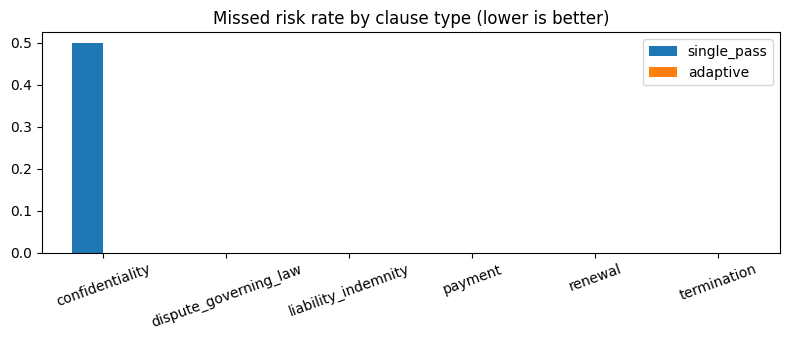

In [ ]:
headline = pd.DataFrame({c: t.loc["all"] for c, t in track_b_tables.items()}).T
for c in RUNS:
    s = pd.DataFrame(json.load(open(RUNS[c] / "summary.json"))["contracts"])
    headline.loc[c, "cost_usd"] = s.cost_usd.sum()
    headline.loc[c, "minutes"] = s.elapsed_s.sum() / 60
    headline.loc[c, "tool_calls"] = s.tool_calls.sum() if "tool_calls" in s else 0   # the baseline has no tools
display(save(headline.round(3), "headline"))

ax = pd.DataFrame({c: t.drop("all")[["false_alarm_rate", "missed_risk_rate"]].stack() for c, t in track_b_tables.items()}) \
       .unstack().loc[:, (slice(None), "missed_risk_rate")].droplevel(1, axis=1) \
       .plot.bar(figsize=(8, 3.5), title="Missed risk rate by clause type (lower is better)", rot=20)
ax.figure.tight_layout(); ax.figure.savefig(OUT / "missed_risk_by_family.png", dpi=150)

## 21. Did the follow-up loop help?

In the adaptive run every row keeps the pre-pass verdict (`prepass_verdict`) next to the final one. For the rows the loop changed, compare both to gold:

* **fixed** wrong → right, **broke** right → wrong, **moved** wrong → a different wrong.

In [ ]:
if "adaptive" in RUNS:
    a = pred[pred.condition == "adaptive"].set_index(["contract_id", "family"]).join(gold.verdict.rename("gold"), how="inner")
    looped = a[a.path != "prepass"]
    changed = looped[looped.verdict_changed.astype(str).str.lower() == "true"]
    before_ok, after_ok = changed.prepass_verdict == changed.gold, changed.verdict == changed.gold
    flips = pd.Series({
        "rows": len(a), "entered_loop": len(looped), "verdict_changed": len(changed),
        "fixed (wrong->right)": int((~before_ok & after_ok).sum()),
        "broke (right->wrong)": int((before_ok & ~after_ok).sum()),
        "moved (wrong->wrong)": int((~before_ok & ~after_ok).sum()),
        "prepass_accuracy": (a.prepass_verdict == a.gold).mean().round(2),
        "final_accuracy": (a.verdict == a.gold).mean().round(2),
    })
    display(save(flips.to_frame("count"), "loop_flips"))
    display(changed[["prepass_verdict", "verdict", "gold", "triggers_fired", "steps"]])

,count
rows,24.00
entered_loop,24.00
verdict_changed,7.00
fixed (wrong->right),3.00
broke (right->wrong),0.00
moved (wrong->wrong),4.00
prepass_accuracy,0.38
final_accuracy,0.50


prepass_verdict verdict        gold  \
contract_id family                                                    
C01         liability_indemnity         unclear   risky  acceptable   
            confidentiality             unclear   risky       risky   
C02         termination                 missing   risky       risky   
            confidentiality          acceptable   risky       risky   
C11         renewal                     unclear   risky  acceptable   
C12         liability_indemnity         unclear   risky  acceptable   
            confidentiality             unclear   risky  acceptable   

                                                                   triggers_fired  \
contract_id family                                                                  
C01         liability_indemnity                                    low_confidence   
            confidentiality                       low_confidence, undefined_terms   
C02         termination                      low_confidence, missing_needs_search   
            confidentiality      low_confidence, quote_not_found, undefined_terms   
C11         renewal              low_confidence, quote_not_found, undefined_terms   
C12         liability_indemnity                   low_confidence, quote_not_found   
            confidentiality      low_confidence, quote_not_found, undefined_terms   

                                 steps  
contract_id family                      
C01         liability_indemnity      5  
            confidentiality          5  
C02         termination              3  
            confidentiality          2  
C11         renewal                  4  
C12         liability_indemnity      4  
            confidentiality          5

### Trajectories: what the loop did

Does the loop stop on its own? Every looped family ends one of two ways: the model calls `finalize`, or a bound stops it (step limit, the same call repeated, no new evidence for two steps, tool-call cap, budget). A healthy agent finalizes most families itself; forced stops are the "looping" we want to see go down. Then: actions per family, and which rows went to the human queue. Rows the labelers disagreed on (`hard`) are where we would want the agent to ask a human.

In [ ]:
if "adaptive" in RUNS:
    tr = pd.read_json(RUNS["adaptive"] / "trace.jsonl", lines=True)
    ended = looped.path.str.replace("forced:", "stopped: ", regex=False).replace({"loop": "model called finalize"})
    display(save(ended.value_counts().to_frame("families"), "how_loops_ended"))
    loop_steps = tr[tr.phase.eq("loop")] if "phase" in tr else tr
    display(save(loop_steps.action.value_counts().to_frame("calls"), "action_mix"))
    print("steps per looped family:", looped.steps.describe()[["mean", "50%", "max"]].round(2).to_dict())

    q = pd.DataFrame(json.load(open(RUNS["adaptive"] / "human_queue.json")))
    if len(q):
        q["kind"] = q.question.str.extract(r"Agent stopped \(([^:)]+)")[0].fillna("agent asked")
        q["hard_row"] = [(r.contract_id, r.family) in hard for r in q.itertuples()]
        display(save(q.groupby("kind").agg(n=("family", "size"), on_hard_rows=("hard_row", "sum")), "human_queue"))
    asked = {(r.contract_id, r.family) for r in q.itertuples()} if len(q) else set()
    hard_in_run = hard & set(a.index)
    print(f"hard rows sent to a human: {len(hard_in_run & asked)} / {len(hard_in_run)};",
          f"easy rows sent to a human: {len(asked - hard)} / {len(set(a.index) - hard)}")

,families
path,
model called finalize,20
stopped: model stopped without finalize,4


,calls
action,
finalize,28
search_contract,16
resolve_defined_term,6
check_cross_reference,6
lookup_rubric,2


steps per looped family: {'mean': 2.42, '50%': 2.0, 'max': 5.0}


,n,on_hard_rows
kind,,
model stopped without finalize,4,0


hard rows sent to a human: 0 / 0; easy rows sent to a human: 4 / 24


## 22. Graders: deterministic checks and an LLM judge

Two kinds of graders score every finding without a human:

* **Deterministic** (free, exact, run on all three conditions): is the output well formed, and does it follow the rules we can check in code?
* **LLM as a judge** (costs API calls): does the quoted evidence actually support the verdict under the rubric, and is the revision ask useful? A judge is only worth trusting if it agrees with people, so we check it against the gold labels and against our own Track C ratings.

In [ ]:
VERDICTS, SEVERITIES = {"acceptable", "risky", "missing", "unclear"}, {"high", "medium", "low", "n/a"}


def deterministic_checks(df, plans=None):
    quoted = df.evidence_text.fillna("").str.strip().replace("NONE FOUND", "") != ""
    checks = pd.DataFrame({
        "valid_verdict": df.verdict.isin(VERDICTS),
        "valid_severity": df.severity.fillna("n/a").isin(SEVERITIES),
        "severity_matches_verdict": (df.verdict == "acceptable") == (df.severity.fillna("n/a") == "n/a"),
        "quote_found_in_contract": df.evidence_verified.astype(str).str.lower() == "true",
        "flag_has_a_quote": ~df.verdict.isin({"risky", "unclear"}) | quoted,
        "missing_has_search_record": (df.verdict != "missing") | df.notes.fillna("").str.contains("search", case=False),
    })
    out = checks.mean()
    if plans is not None:                 # revision plan sorted by rubric §7: severity, then verdict
        sev, ver = {"high": 0, "medium": 1, "low": 2}, {"risky": 0, "missing": 1, "unclear": 2}
        keys = [[(sev.get(i.get("severity"), 3), ver.get(i.get("verdict"), 3)) for i in items] for items in plans.values()]
        out["plan_in_rubric_order"] = sum(k == sorted(k) for k in keys) / max(len(keys), 1)
    return out


def load_plans(c):          # the baseline (04) writes no revision plan
    p = RUNS[c] / "revision_plans.json"
    return json.load(open(p)) if p.exists() else None


det = pd.DataFrame({c: deterministic_checks(pred[pred.condition == c], load_plans(c)) for c in RUNS}).round(2)
display(save(det, "deterministic_checks"))

,single_pass,adaptive
flag_has_a_quote,1.00,1.00
missing_has_search_record,0.88,0.92
plan_in_rubric_order,NaN,1.00
quote_found_in_contract,0.79,0.83
severity_matches_verdict,1.00,1.00
valid_severity,1.00,1.00
valid_verdict,1.00,1.00


### LLM as a judge

The judge sees the rubric for the family, the agent's verdict, its quote and its notes, and answers two questions on a 1–3 scale. It never sees the gold label. Set `JUDGE_MODEL` to a stronger model than the agent's if the course credit allows, so the judge is not grading its own mistakes. `MAX_JUDGE_CALLS` caps the cost.

In [32]:
import re
from openai import OpenAI

JUDGE_MODEL = "@30875-fall26-openai/gpt-5-nano"     # a stronger model is better if available
MAX_JUDGE_CALLS = 300
judge_client = OpenAI(api_key=api_key, base_url="https://api.portkey.ai/v1") if api_key else None

rubric_text = (DATA_DIR / "rubric_v1.md").read_text()
RUBRIC_BY_FAMILY = {f: re.search(rf"^## \d+\. {f}\n(.*?)(?=^## )", rubric_text, re.S | re.M).group(1) for f in FAMILIES}

FINDING_JUDGE = """You grade a contract reviewer's finding for a small-business customer, using this rubric:

{rubric}

Finding: family={family}, verdict={verdict}, severity={severity}
Quoted evidence ({section}): "{quote}"
Reviewer's notes: {notes}

Answer in JSON only: {{"supported": 1-3, "answers_rubric": 1-3, "reason": "one sentence"}}
supported: 3 = the quote clearly justifies this verdict and severity under the rubric, 2 = partly, 1 = it does not (wrong verdict, wrong severity, or the quote is about something else).
answers_rubric: 3 = the notes address the rubric sub-criterion that decides this family, 1 = they do not."""

PLAN_JUDGE = """A small-business customer will send this ask to a vendor about a contract clause.
Finding: {family} ({verdict}, {severity}). Clause: "{quote}"
Ask: {ask}
Fallback: {fallback}

Answer in JSON only: {{"grounded": 1-3, "specific": 1-3, "actionable": 1-3, "reason": "one sentence"}}
grounded: follows from the clause. specific: says exactly what to change (a number, a period, a cap). actionable: could be sent as is."""

calls = 0


def judge(prompt):
    global calls
    if judge_client is None or calls >= MAX_JUDGE_CALLS:
        return {}
    calls += 1
    reply = judge_client.chat.completions.create(model=JUDGE_MODEL, messages=[{"role": "user", "content": prompt}])
    text = reply.choices[0].message.content or ""
    try:
        out = json.loads(text[text.index("{"):text.rindex("}") + 1])
    except ValueError:
        return {}
    for k, v in out.items():                        # nano sometimes answers [2] or "2" instead of 2
        if k != "reason":
            v = v[0] if isinstance(v, list) and v else v
            out[k] = pd.to_numeric(v, errors="coerce") if not isinstance(v, (list, dict)) else float("nan")
    return out


def judge_findings(df):
    out = []
    for r in df.itertuples():
        j = judge(FINDING_JUDGE.format(rubric=RUBRIC_BY_FAMILY[r.family], family=r.family, verdict=r.verdict,
                                       severity=r.severity, section=r.section_ref, quote=str(r.evidence_text)[:800],
                                       notes=str(r.notes)[:600]))
        out.append({"contract_id": r.contract_id, "family": r.family, **j})
    return pd.DataFrame(out).set_index(["contract_id", "family"])


JUDGED = {}
for c in RUNS:
    JUDGED[c] = judge_findings(pred[pred.condition == c]).join(gold.verdict.rename("gold")) \
        .join(pred[pred.condition == c].set_index(["contract_id", "family"]).verdict)
print(calls, "judge calls")

48 judge calls


Is the judge trustworthy? If it is, findings whose verdict matches gold should get high `supported` scores and wrong ones low. `judge_separates` is the mean score on right findings minus the mean on wrong ones (bigger is better; near 0 means the judge cannot tell them apart).

In [33]:
rows = {}
for c, j in JUDGED.items():
    if "supported" not in j:
        continue
    right = j.verdict == j.gold
    rows[c] = {"mean_supported": j.supported.mean(), "mean_answers_rubric": j.answers_rubric.mean(),
               "supported_when_right": j.supported[right].mean(), "supported_when_wrong": j.supported[~right].mean(),
               "judge_separates": j.supported[right].mean() - j.supported[~right].mean(),
               "judge_flags_wrong (score 1)": (j.supported[~right] == 1).mean()}
if rows:
    display(save(pd.DataFrame(rows).T.round(2), "llm_judge_findings"))

,mean_supported,mean_answers_rubric,supported_when_right,supported_when_wrong,judge_separates,judge_flags_wrong (score 1)
single_pass,2.17,2.71,2.56,1.93,0.62,0.33
adaptive,2.38,2.75,2.67,2.08,0.58,0.33


## 23. Track C: are the recommendations useful?

Same grader for every condition (this cell comes from Kayla's `06_baseline_and_scoring.ipynb`), three criteria rated 1–3 (`grounded`, `specific`, `actionable`), and the same `PLAN_JUDGE` prompt — only the source differs by condition, because the two systems emit a recommendation in different shapes:

* the **agent** writes a prioritized `revision_plans.json` with an `ask` and a `fallback` per finding;
* the **baseline** has no aggregation step, so `04` writes one `recommendation` per flagged row and `plan_items` builds the same record from it, with an empty `fallback`.

**Your ratings survive a re-run.** The model is not deterministic, so every run rewords the asks. Two things protect the ratings:

1. Each item is keyed by `condition + contract_id + family`, never by its position in the list. A family never moves, so a rating always lands on the item it was written for. (The `id` column is kept only to show the rubric §7 order.)
2. Each item carries an `ask_hash`, a fingerprint of the ask's wording. If a re-run rewords an ask, the key still matches but the hash does not, and the next cell tells you how many of your ratings were written against older wording.

**The LLM judge is cached** to `scores/llm_judge_plan.csv` and only scores items it has not seen (same key *and* same wording). So the judge's numbers stay fixed once produced, a re-run costs nothing for unchanged items, and the figure in the report does not drift.

**Freeze the run you rate.** Once you have the run you intend to report, keep `runs/` and `scores/llm_judge_plan.csv` (the last cell downloads both) and commit them. Rate against that, and do not re-run afterwards. The ratings belong to one run; the code tells you when they have drifted, but it cannot re-rate for you.

In [36]:
import hashlib

CRITERIA = ["grounded", "specific", "actionable"]
RATINGS_KEY = ["condition", "contract_id", "family"]   # stable across runs; the §7 `id` is not


def ask_id(text):
    """Fingerprint of an ask's wording, so a re-run can say which items actually changed."""
    return hashlib.sha1(" ".join(str(text or "").split()).lower().encode()).hexdigest()[:8]


def plan_items(c):
    """Rateable recommendations for one condition, in one shape.
    The agent writes revision_plans.json; the baseline writes one recommendation per flagged row."""
    COLS = ["condition", "contract_id", "family", "id", "severity", "evidence", "ask", "fallback", "ask_hash"]
    p = RUNS[c] / "revision_plans.json"
    if p.exists():
        df = pd.DataFrame([{"contract_id": cid, "id": it["id"], "family": it["family"],
                            "severity": it.get("severity", ""),
                            "evidence": str(it.get("evidence_text", ""))[:300],
                            "ask": it.get("ask", ""), "fallback": it.get("fallback", "")}
                           for cid, items in json.load(open(p)).items() for it in items])
    else:
        d = pred[(pred.condition == c) & (pred.verdict != "acceptable")].copy()
        if "recommendation" not in d:               # no plan and no recommendation: nothing to rate
            return pd.DataFrame(columns=COLS)
        d = d[d.recommendation.fillna("").str.strip() != ""]
        d["fam_order"] = d.family.map({f: i for i, f in enumerate(FAMILIES)})
        d = d.sort_values(["contract_id", "fam_order"])
        d["id"] = d.groupby("contract_id").cumcount() + 1
        df = pd.DataFrame({"contract_id": d.contract_id, "id": d.id, "family": d.family,
                           "severity": d.severity, "evidence": d.evidence_text.fillna("").str[:300],
                           "ask": d.recommendation.fillna(""), "fallback": ""}).reset_index(drop=True)
    if not len(df):
        return pd.DataFrame(columns=COLS)
    df["condition"], df["ask_hash"] = c, df.ask.map(ask_id)
    return df[COLS]


SHEET = {c: plan_items(c) for c in RUNS}
template = pd.concat(SHEET.values(), ignore_index=True)
for k in CRITERIA:
    template[k] = ""
template.to_csv(OUT / "ratings_template.csv", index=False)
for c, s in SHEET.items():
    print(f"{c}: {len(s)} items to rate")
print("hand-rating sheet ->", OUT / "ratings_template.csv")

# --- the judge, cached: only score an item whose key AND wording we have not judged before ---
JUDGE_CACHE = OUT / "llm_judge_plan.csv"
KEYH = RATINGS_KEY + ["ask_hash"]
cached = pd.read_csv(JUDGE_CACHE) if JUDGE_CACHE.exists() else pd.DataFrame(columns=KEYH + CRITERIA)
seen = set(map(tuple, cached[KEYH].astype(str).values)) if len(cached) else set()
todo = [r for s in SHEET.values() for r in s.itertuples()
        if (str(r.condition), str(r.contract_id), str(r.family), str(r.ask_hash)) not in seen]
print(f"judge: {len(cached)} cached, {len(todo)} to score")

fresh = pd.DataFrame([{"condition": r.condition, "contract_id": r.contract_id, "family": r.family,
                       "ask_hash": r.ask_hash,
                       **judge(PLAN_JUDGE.format(family=r.family, verdict="", severity=r.severity,
                                                 quote=r.evidence, ask=r.ask, fallback=r.fallback))}
                      for r in todo])
plan_judge = pd.concat([cached, fresh], ignore_index=True) if len(fresh) else cached
plan_judge = plan_judge.drop_duplicates(KEYH, keep="last")
if len(plan_judge) and "grounded" in plan_judge:
    plan_judge.to_csv(JUDGE_CACHE, index=False)     # keep it: a re-judge costs money and drifts
    display(plan_judge.groupby("condition")[CRITERIA].mean().round(2))
print(calls, "judge calls this session")

single_pass: 0 items to rate
adaptive: 20 items to rate
hand-rating sheet -> scores/ratings_template.csv
judge: 0 cached, 20 to score


/tmp/ipykernel_547/705456105.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  plan_judge = pd.concat([cached, fresh], ignore_index=True) if len(fresh) else cached


,grounded,specific,actionable
condition,,,
adaptive,2.55,2.67,2.95


68 judge calls this session


In [37]:
def read_ratings(p):
    d = pd.read_csv(p)
    if "condition" not in d:                        # a hand sheet covering one condition only
        d["condition"] = next(iter(RUNS))
    for k in CRITERIA:
        d[k] = pd.to_numeric(d.get(k), errors="coerce")
    return d


rated = {p.stem.split("_", 1)[1]: read_ratings(p) for p in sorted(Path(".").glob("ratings_*.csv"))
         if p.stem != "ratings_template"}
if len(plan_judge) and "grounded" in plan_judge:
    rated["llm_judge"] = plan_judge

now = template.set_index(RATINGS_KEY).ask_hash.astype(str).rename("now").reset_index()


def aligned(d, who):
    """One rating per item, for items that still exist in this run.
    Where a rater has both an old and a current wording, the current one wins; the rest are reported."""
    m = d.merge(now, on=RATINGS_KEY, how="left")
    lost = int(m.now.isna().sum())
    m = m[m.now.notna()].dropna(subset=CRITERIA, how="all").copy()
    m["current"] = m.ask_hash.astype(str) == m.now if "ask_hash" in m else True
    m = m.sort_values("current").drop_duplicates(RATINGS_KEY, keep="last")   # keep the current wording
    stale = int((~m.current).sum())
    note = f"{len(m)}/{len(now)} items rated"
    if stale:
        note += f"; {stale} only rated against an older wording (re-rate those)"
    if lost:
        note += f"; {lost} ratings match no item in this run"
    print(f"  {who}: {note}")
    return m.set_index(RATINGS_KEY)[CRITERIA]


use = {w: a for w, a in ((w, aligned(d, w)) for w, d in rated.items()) if len(a)}

if use:
    display(save(pd.concat({who: a.groupby(level="condition").mean().round(2) for who, a in use.items()},
                           names=["rater"]), "track_c_means"))
    names = list(use)
    pairs = {}
    for i, a in enumerate(names):
        for b in names[i + 1:]:
            both = use[a].merge(use[b], on=RATINGS_KEY, suffixes=("_a", "_b")).dropna()
            if len(both) > 1:
                pairs[f"{a} vs {b}"] = {k: cohen_kappa_score(both[k + "_a"].astype(int),
                                                             both[k + "_b"].astype(int),
                                                             weights="quadratic") for k in CRITERIA}
    if pairs:
        display(save(pd.DataFrame(pairs).T.round(2), "track_c_agreement"))   # judge vs human = trust the judge?
else:
    print("no usable ratings yet. Fill in", OUT / "ratings_template.csv",
          "and put each finished copy next to this notebook as ratings_<name>.csv;",
          "the LLM judge appears here too once it has run with an API key.")

  llm_judge: 20/20 items rated


,,grounded,specific,actionable
rater,condition,,,
llm_judge,adaptive,2.55,2.67,2.95


## 24. Retrieval check: is the pre-pass reading the right passages?

No model calls (only embeddings for `dense` and `hybrid`). For every contract × family, the "relevant" text is where the gold quotes and CUAD's highlights are. For each query strategy, retrieval mode and chunk size we measure, with the same k as the pre-pass:

* **hit@k**: at least one retrieved chunk overlaps a relevant passage
* **MRR**: 1 / rank of the first relevant chunk (higher = found earlier)
* **coverage**: share of the relevant passages that the retrieved chunks touch (the pre-pass can only quote what it sees)

Query strategies: `name` (the family name), `keywords` (the rubric's keyword list, what the agent uses), `multi` (one query per rubric sub-criterion, fused with reciprocal-rank fusion). Choose on **dev**, report **test**. What retrieval misses here is what the follow-up loop's `search_contract` and `check_cross_reference` have to recover.

In [42]:
from tqdm.notebook import tqdm

def retrieval_eval_optimized(
    strategies=("name", "keywords", "multi"),
    modes=("sparse", "dense", "hybrid"),
    chunkings=((110, 30),), # Evaluate one chunking configuration first to save time
    k=BOUNDS.prepass_top_k,
    limit_split="dev"       # Default to evaluating 'dev' split contracts only (C01, C02, C11, C12)
):
    rows = []
    target_cids = sorted([cid for cid, m in load_meta().items() if m["split"] == limit_split]) if limit_split else sorted(meta)

    total_steps = len(target_cids) * len(chunkings) * len(FAMILIES)
    pbar = tqdm(total=total_steps, desc="Retrieval Progress")

    for cid in target_cids:
        for words, overlap in chunkings:
            c = Contract.load(DATA_DIR / "contracts" / f"{cid}.txt", meta[cid], chunk_words=words, overlap=overlap)
            r = Retriever(c, EMBEDDER)
            for fam in FAMILIES:
                spans = relevant_spans(c, fam)
                if not spans:
                    pbar.update(1)
                    continue
                touches = lambda i, sp: c.chunks[i].start < sp[1] and sp[0] < c.chunks[i].end
                for mode in (modes if EMBEDDER else ("sparse",)):
                    for strategy in strategies:
                        top = retrieve(r, fam, strategy, mode, k)
                        first = next((n for n, i in enumerate(top) if any(touches(i, sp) for sp in spans)), None)
                        rows.append({
                            "split": meta[cid]["split"],
                            "family": fam,
                            "chunks": f"{words}/{overlap}",
                            "mode": mode,
                            "query": strategy,
                            "hit@k": first is not None,
                            "mrr": 0 if first is None else 1 / (first + 1),
                            "coverage": sum(any(touches(i, sp) for i in top) for sp in spans) / len(spans),
                            "words_read": sum(len(c.chunks[i].text.split()) for i in top)
                        })
                pbar.update(1)
    pbar.close()
    return pd.DataFrame(rows)

# Run the optimized retrieval evaluation
print("Starting optimized retrieval evaluation (dev split, single chunking config)... ")
ret = retrieval_eval_optimized()

table = ret.groupby(["split", "chunks", "mode", "query"])[["hit@k", "mrr", "coverage", "words_read"]].mean().round(3)
table.to_csv(OUT / "retrieval_eval.csv")
display(table.loc["dev"].sort_values("coverage", ascending=False))

Starting optimized retrieval evaluation (dev split, single chunking config)... 


Retrieval Progress:   0%|          | 0/24 [00:00<?, ?it/s]

hit@k    mrr  coverage  words_read
chunks mode   query                                       
110/30 hybrid multi     1.000  0.788     0.942       440.0
              keywords  1.000  0.910     0.887       440.0
       sparse multi     0.958  0.715     0.862       440.0
       dense  multi     1.000  0.854     0.859       440.0
              name      0.958  0.812     0.840       440.0
       sparse keywords  0.958  0.847     0.819       440.0
       dense  keywords  0.958  0.837     0.814       440.0
       hybrid name      0.958  0.767     0.770       440.0
       sparse name      0.792  0.597     0.604       440.0

## 25. Download everything

One zip with every run folder and every score table, for the report and the submission.

In [ ]:
print(sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    !zip -qr results_{SPLIT}.zip runs scores
    files.download(f"results_{SPLIT}.zip")